This notebook implements the **original Transformer** (Vaswani et al., 2017, *Attention Is All You Need*) in pure NumPy — the **full encoder–decoder architecture**, with every intermediate matrix printed and every formula written out.

The task here is **autoregressive next-token prediction**:

* the **encoder** reads a *prefix* of the sentence (9 tokens);
* the **decoder** predicts the *continuation* of that same sentence (6 tokens), one token at a time, each prediction conditioned on the prefix **and** on everything it has already generated.

This is the "prefix-LM" arrangement: same architecture as translation, different task. Nothing about the encoder, the decoder, or the cross-attention changes — only what the two sequences contain.

The chain is carried all the way to the end:

**tokens → IDs → embeddings → positional encoding → encoder (MHA + FFN) → decoder (masked MHA + cross-attention + FFN) → linear projection → logits → softmax → next token**

---

## The Autoregressive Factorization

"Autoregressive" means the model factorizes the probability of the whole continuation into a product of next-token probabilities, each conditioned only on what came before:

$$P(y_1, y_2, \dots, y_n \mid x) \;=\; \prod_{t=1}^{n} P(y_t \mid y_1, \dots, y_{t-1},\, x)$$

Two architectural components enforce the "only on what came before" part, and both are implemented below:

1. **Shift right** — at position $t$ the decoder is fed $y_{t-1}$, never $y_t$.
2. **Causal mask** — position $t$ cannot attend to positions $> t$.

The conditioning on $x$ (the prefix) enters through **cross-attention**, which is the one place the encoder and decoder touch:

$$Q \text{ from the \textbf{decoder}}, \qquad K, V \text{ from the \textbf{encoder}}$$

**Honest caveat, stated once:** the weights here are *random*, not trained. Every number is computed correctly, but the predicted token is meaningless. The purpose is the mechanics of the forward pass, not linguistic quality.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)          # reproducibility
np.set_printoptions(precision=3, suppress=True, linewidth=160)

print("NumPy:", np.__version__)

NumPy: 2.4.4


In [2]:
# ============================================================================
#  DISPLAY HELPERS — used at every matrix multiplication from here on.
#  They print BOTH operands, the result, one worked element, and the shape rule.
# ============================================================================

def expand(u, v, per_line=4):
    # Write out a dot product term by term
    terms = [f"({a:+.4f})*({b:+.4f})" for a, b in zip(u, v)]
    lines, out = [], ""
    for i, t in enumerate(terms):
        out += t + (" + " if i < len(terms) - 1 else "")
        if (i + 1) % per_line == 0:
            lines.append(out); out = ""
    if out: lines.append(out)
    return "\n      ".join(lines)

def show_matmul(A, B, C, na="A", nb="B", nc="C", i=0, j=0,
                max_cols=12, rows_A=None, cols_B=None, note=None):
    """Print both operands of A @ B = C, then verify one element by hand."""
    print("=" * 78)
    print(f"  {na} {A.shape}   @   {nb} {B.shape}   =   {nc} {C.shape}")
    print(f"  shape rule: ({A.shape[0]} x {A.shape[1]}) @ ({B.shape[0]} x {B.shape[1]})"
          f" -> ({A.shape[0]} x {B.shape[1]})   inner dim {A.shape[1]} cancels")
    if note: print(f"  {note}")
    print("=" * 78)

    def show(M, name, labels=None, cap=max_cols):
        cut = M.shape[1] > cap
        Ms = M[:, :cap] if cut else M
        print(f"\n{name} =" + (f"   [showing first {cap} of {M.shape[1]} columns]" if cut else ""))
        for r in range(Ms.shape[0]):
            lab = f"{labels[r]:>10} | " if labels is not None else ""
            print("   " + lab + "  ".join(f"{v:+8.3f}" for v in Ms[r]))

    show(A, na, rows_A)
    show(B, nb)
    show(C, nc, rows_A)

    print(f"\n  worked element  {nc}[{i},{j}]  =  row {i} of {na}  .  column {j} of {nb}")
    print(f"      row  {i} of {na} = {np.round(A[i], 4)}")
    print(f"      col  {j} of {nb} = {np.round(B[:, j], 4)}")
    print(f"      {expand(A[i], B[:, j])}")
    val = float(A[i] @ B[:, j])
    print(f"      = {val:+.6f}   |  from array: {C[i, j]:+.6f}   |  "
          f"MATCH: {np.isclose(val, C[i, j])}")

def show_elementwise(A, B, C, na, nb, nc, op="+", rows=None):
    """Print an element-wise operation (residual add) with both operands."""
    print("=" * 78)
    print(f"  {nc} = {na} {op} {nb}      all three are {A.shape} — element-wise, no mixing")
    print("=" * 78)
    for r in range(A.shape[0]):
        lab = f"{rows[r]:>10} | " if rows is not None else f"{r:>10} | "
        print(f"\n{lab}")
        print("   " + f"{na:>14}: " + "  ".join(f"{v:+8.3f}" for v in A[r]))
        print("   " + f"{nb:>14}: " + "  ".join(f"{v:+8.3f}" for v in B[r]))
        print("   " + f"{nc:>14}: " + "  ".join(f"{v:+8.3f}" for v in C[r]))
    print(f"\n  check element [0,0]: {A[0,0]:+.6f} {op} {B[0,0]:+.6f} = {C[0,0]:+.6f}   "
          f"MATCH: {np.isclose(A[0,0] + B[0,0] if op=='+' else A[0,0]-B[0,0], C[0,0])}")

def show_masked(M, mask, name="scores", rows=None):
    """Print a score matrix with blocked entries as -inf instead of -1.0e+09.

    Mixing -1e9 with ordinary scores forces numpy into scientific notation and
    the triangular structure becomes unreadable, so blocked cells are printed
    symbolically instead.
    """
    print(f"{name} =   (blocked entries shown as -inf)")
    for r in range(M.shape[0]):
        lab = f"{rows[r]:>10} | " if rows is not None else f"{r:>10} | "
        cells_ = ["    -inf" if mask[r, c] else f"{M[r, c]:+8.3f}"
                  for c in range(M.shape[1])]
        print("   " + lab + "  ".join(cells_))

def show_weights_masked(A, mask, name="A", rows=None):
    """Print softmax weights, showing blocked entries as a hard 0."""
    print(f"{name} =   (blocked entries are exactly 0)")
    for r in range(A.shape[0]):
        lab = f"{rows[r]:>10} | " if rows is not None else f"{r:>10} | "
        cells_ = ["       0" if mask[r, c] else f"{A[r, c]:8.4f}"
                  for c in range(A.shape[1])]
        print("   " + lab + "  ".join(cells_))

print("Display helpers ready: show_matmul, show_elementwise, show_masked, show_weights_masked, expand.")


Display helpers ready: show_matmul, show_elementwise, show_masked, show_weights_masked, expand.


---
# 1. Task & Hyperparameters

The sentence is split into two parts:

| | content | length | fed to |
|---|---|---|---|
| **prefix** $x$ | `the cat sat on the mat and was looking` | 9 | encoder |
| **continuation** $y$ | `at a tiny mouse running by` | 6 | decoder (autoregressively) |

The decoder must produce `at a tiny mouse running by <eos>`, one token at a time.

The two lengths are deliberately **different** (9 vs 6). This matters: it forces the cross-attention matrix to be rectangular ($n_{tgt} \times n_{src}$), which is easy to get wrong when both lengths are equal, and it makes the shapes unambiguous when reading the printouts.

Note that both halves share **one vocabulary** — they are two parts of the same English sentence. In the translation version of this architecture the two halves would be two different languages; the machinery is identical either way.

| Symbol | Meaning | Value |
|---|---|---|
| $n_{src}$ | prefix length | 9 |
| $n_{tgt}$ | decoder input length | 7 (`<sos>` + 6 words) |
| $d_{model}$ | embedding / model width | 8 |
| $h$ | number of attention heads | 2 |
| $d_k = d_v = d_{model}/h$ | width of one head | 4 |
| $d_{ff}$ | inner width of the FFN | 32 ($=4 d_{model}$) |
| $V$ | vocabulary size | 500 |

In [3]:
D_MODEL   = 8            # d_model
N_HEADS   = 2            # h
D_K       = D_MODEL // N_HEADS   # d_k = d_v = 4
D_FF      = 4 * D_MODEL  # 32
VOCAB_SIZE = 500         # token IDs live in [0, 500)

full_sentence = "the cat sat on the mat and was looking at a tiny mouse running by"
all_tokens = full_sentence.split()

SPLIT = 9                      # first 9 tokens -> encoder, rest -> decoder
src_tokens = all_tokens[:SPLIT]        # prefix, read by the encoder
tgt_tokens = all_tokens[SPLIT:]        # continuation, generated by the decoder

print(f"Full sentence ({len(all_tokens)} tokens): {all_tokens}\n")
print(f"PREFIX       -> encoder ({len(src_tokens)} tokens): {src_tokens}")
print(f"CONTINUATION -> decoder ({len(tgt_tokens)} tokens): {tgt_tokens}")
print(f"\nd_model={D_MODEL}, h={N_HEADS}, d_k={D_K}, d_ff={D_FF}, V={VOCAB_SIZE}")

Full sentence (15 tokens): ['the', 'cat', 'sat', 'on', 'the', 'mat', 'and', 'was', 'looking', 'at', 'a', 'tiny', 'mouse', 'running', 'by']

PREFIX       -> encoder (9 tokens): ['the', 'cat', 'sat', 'on', 'the', 'mat', 'and', 'was', 'looking']
CONTINUATION -> decoder (6 tokens): ['at', 'a', 'tiny', 'mouse', 'running', 'by']

d_model=8, h=2, d_k=4, d_ff=32, V=500


---
# 2. Vocabulary & Token IDs

As requested, token IDs are **random integers in [50, 500)** — this mimics a real tokenizer, where the ID is an arbitrary index into a vocabulary, carrying no meaning by itself.

Three IDs are reserved below 50, as is standard:

* `<pad>` = 0 — padding (not used here, sequences are not batched)
* `<sos>` = 1 — start of sequence, fed to the decoder at position 0
* `<eos>` = 2 — end of sequence, what the decoder must predict last

Prefix and continuation share one vocabulary of size $V = 500$ — they are halves of the same sentence. Note that the repeated word `"the"` receives the **same** ID at both of its positions — an embedding table is a lookup by ID, so identical words start from identical vectors. What makes them differ later is *positional encoding* and *context*.

In [4]:
PAD_ID, SOS_ID, EOS_ID = 0, 1, 2

# Unique words across both sentences, in order of first appearance
unique_words = []
for w in src_tokens + tgt_tokens:
    if w not in unique_words:
        unique_words.append(w)

# Assign each unique word a distinct random ID in [50, 500)
rng_ids = np.random.default_rng(0)
chosen  = rng_ids.choice(np.arange(50, VOCAB_SIZE), size=len(unique_words), replace=False)

word2id = {"<pad>": PAD_ID, "<sos>": SOS_ID, "<eos>": EOS_ID}
for w, i in zip(unique_words, chosen):
    word2id[w] = int(i)
id2word = {i: w for w, i in word2id.items()}

src_ids = np.array([word2id[w] for w in src_tokens])
tgt_ids = np.array([word2id[w] for w in tgt_tokens])

print(f"Vocabulary: {len(word2id)} entries used out of V={VOCAB_SIZE}\n")
print("PREFIX token -> ID  (encoder)")
for w, i in zip(src_tokens, src_ids):
    print(f"  {w:<9} -> {i}")
print("\nCONTINUATION token -> ID  (decoder)")
for w, i in zip(tgt_tokens, tgt_ids):
    print(f"  {w:<9} -> {i}")

print(f"\nNote: 'the' appears at positions 0 and 4, both with ID {word2id['the']}.")

Vocabulary: 17 entries used out of V=500

PREFIX token -> ID  (encoder)
  the       -> 83
  cat       -> 168
  sat       -> 458
  on        -> 328
  the       -> 83
  mat       -> 421
  and       -> 185
  was       -> 276
  looking   -> 274

CONTINUATION token -> ID  (decoder)
  at        -> 127
  a         -> 340
  tiny      -> 68
  mouse     -> 57
  running   -> 412
  by        -> 322

Note: 'the' appears at positions 0 and 4, both with ID 83.


---
# 3. Weight Initialization

The old notebook drew every weight from `np.random.rand`, i.e. $\mathcal{U}(0,1)$: **all entries positive, mean 0.5**.

For $y = xW$ with $W \in \mathbb{R}^{8\times 8}$ and all entries positive, each output is a sum of 8 positive products, so $\mathbb{E}[y] \approx 8 \cdot 0.5 \cdot \mathbb{E}[x] = 4\,\mathbb{E}[x]$. The signal is **multiplied by ~4 at every matrix product**, and it is never re-centred because there is no LayerNorm. Chaining ≈ 8 such products gives $4^8 \approx 65\,000$ — exactly the order of magnitude seen in the old output (≈ 80 000). Worse, since all rows grow in the *same* direction, they become nearly parallel and the row-to-row differences vanish: the tokens lose their identity.

**Xavier/Glorot** initialization fixes the scale:

$$W_{ij} \sim \mathcal{U}(-a, a), \qquad a = \sqrt{\frac{6}{fan_{in} + fan_{out}}}$$

which keeps $\mathrm{Var}(y) \approx \mathrm{Var}(x)$ and $\mathbb{E}[y] = 0$.

In [5]:
def xavier(fan_in, fan_out, rng=np.random):
    # Glorot uniform initialization: zero-mean, variance-preserving
    a = np.sqrt(6.0 / (fan_in + fan_out))
    return rng.uniform(-a, a, size=(fan_in, fan_out))

# Quick demonstration of the failure mode of the old init
x = np.random.rand(15, 8)
bad, good = x.copy(), x.copy()
for _ in range(8):
    bad  = bad  @ np.random.rand(8, 8)      # old notebook style
    good = good @ xavier(8, 8)              # this notebook
print(f"After 8 chained matmuls, no LayerNorm:")
print(f"  U(0,1) init  -> mean |value| = {np.abs(bad).mean():10.2f}   "
      f"row-to-row std = {bad.std(axis=0).mean():.4f}")
print(f"  Xavier init  -> mean |value| = {np.abs(good).mean():10.4f}   "
      f"row-to-row std = {good.std(axis=0).mean():.4f}")
print("\nThe U(0,1) rows have exploded AND collapsed onto each other.")

After 8 chained matmuls, no LayerNorm:
  U(0,1) init  -> mean |value| =   33138.98   row-to-row std = 9033.2708
  Xavier init  -> mean |value| =     0.2531   row-to-row std = 0.1784

The U(0,1) rows have exploded AND collapsed onto each other.


---
# 4. Embeddings

The embedding table is $E \in \mathbb{R}^{V \times d_{model}} = \mathbb{R}^{500 \times 8}$. Looking up token ID $t$ means taking row $t$: this is exactly a one-hot vector times $E$,

$$\mathrm{emb}(t) = \mathbf{e}_t^\top E, \qquad \mathbf{e}_t \in \{0,1\}^{V}$$

but implemented as indexing, since the matrix product would be wasteful.

**Scaling by $\sqrt{d_{model}}$.** The paper multiplies the embeddings by $\sqrt{d_{model}}$ before adding the positional encoding (Section 3.4). The reason is scale matching: positional encodings are sines and cosines with values in $[-1, 1]$, while embeddings initialized with variance $1/d_{model}$ have entries around $\pm 0.35$. Without the scaling, the positional signal would dominate the semantic signal. Here $\sqrt{8} \approx 2.83$.

In [6]:
# Embedding table: rows drawn with std = 1/sqrt(d_model)
E = np.random.randn(VOCAB_SIZE, D_MODEL) / np.sqrt(D_MODEL)
print(f"Embedding table E shape: {E.shape}")

scale = np.sqrt(D_MODEL)
src_emb = E[src_ids] * scale        # (9, 8)  -- the prefix
print(f"\nsrc_emb = E[src_ids] * sqrt({D_MODEL}) = E[src_ids] * {scale:.4f}")
print(f"Prefix embeddings shape: {src_emb.shape}\n")
for w, i, v in zip(src_tokens, src_ids, src_emb):
    print(f"  {w:<9} (id {i:>3}) -> {np.round(v, 3)}")

print(f"\nCheck that both occurrences of 'the' are identical before PE:")
print(f"  position 0: {np.round(src_emb[0], 3)}")
print(f"  position 4: {np.round(src_emb[4], 3)}")
print(f"  identical? {np.allclose(src_emb[0], src_emb[4])}")

Embedding table E shape: (500, 8)

src_emb = E[src_ids] * sqrt(8) = E[src_ids] * 2.8284
Prefix embeddings shape: (9, 8)

  the       (id  83) -> [-0.1   -0.204 -0.878 -0.827 -0.226  0.367  0.914 -0.803]
  cat       (id 168) -> [-0.685  0.791 -1.97   0.893 -1.211  0.731  0.014 -0.954]
  sat       (id 458) -> [ 1.393  0.839  0.873 -0.966 -0.079 -0.3   -1.006  0.36 ]
  on        (id 328) -> [ 1.221 -0.877  1.712 -1.748  0.435  0.475 -0.796  0.424]
  the       (id  83) -> [-0.1   -0.204 -0.878 -0.827 -0.226  0.367  0.914 -0.803]
  mat       (id 421) -> [ 0.234  1.035 -0.836  1.424 -0.092 -0.888  0.998 -0.287]
  and       (id 185) -> [-0.536 -1.707 -1.117  1.236 -0.156 -0.548  0.16   0.502]
  was       (id 276) -> [-0.864  1.279  1.042  0.584 -0.13   0.58  -0.707  0.856]
  looking   (id 274) -> [ 0.234 -0.249  1.201  0.14  -1.967 -1.117 -0.186  0.31 ]

Check that both occurrences of 'the' are identical before PE:
  position 0: [-0.1   -0.204 -0.878 -0.827 -0.226  0.367  0.914 -0.803]
  posi

---
# 5. Positional Encoding

Self-attention is a **set** operation: it computes a weighted sum over positions, and the weights depend only on content. Nothing in $QK^\top$ knows that position 3 comes after position 2. Order must therefore be injected into the input itself.

The sinusoidal encoding from the paper, for position $pos$ and dimension index $i$:

$$PE_{(pos,\,2i)} = \sin\!\left(\frac{pos}{10000^{2i/d_{model}}}\right), \qquad
PE_{(pos,\,2i+1)} = \cos\!\left(\frac{pos}{10000^{2i/d_{model}}}\right)$$

With $d_{model} = 8$ there are 4 frequency pairs, $i = 0, 1, 2, 3$:

| $i$ | columns | wavelength $2\pi \cdot 10000^{2i/8}$ |
|---|---|---|
| 0 | 0, 1 | $2\pi \approx 6.28$ |
| 1 | 2, 3 | $2\pi \cdot 10 \approx 62.8$ |
| 2 | 4, 5 | $2\pi \cdot 100 \approx 628$ |
| 3 | 6, 7 | $2\pi \cdot 1000 \approx 6283$ |

Fast columns encode fine-grained local position; slow columns encode coarse absolute position. The property that makes this choice useful is that $PE_{pos+k}$ is a **fixed linear function** of $PE_{pos}$ (a 2-D rotation by angle $k\omega_i$ in each frequency pair), so relative offsets are linearly recoverable by the attention weights.

In [7]:
def positional_encoding(seq_len, d_model):
    pos = np.arange(seq_len)[:, None]                      # (n, 1)
    i   = np.arange(0, d_model, 2)                         # 0, 2, 4, 6
    div = np.exp(i * -(np.log(10000.0) / d_model))         # 1 / 10000^(2i/d_model)
    pe = np.zeros((seq_len, d_model))
    pe[:, 0::2] = np.sin(pos * div)
    pe[:, 1::2] = np.cos(pos * div)
    return pe

PE_src = positional_encoding(len(src_tokens), D_MODEL)
print(f"PE_src shape: {PE_src.shape}\n{np.round(PE_src, 4)}")

# Hand-verification of one entry, PE[3, 2]  (pos=3, dim=2 -> i=1, even -> sine)
omega_1 = 1.0 / (10000 ** (2 * 1 / D_MODEL))
manual  = np.sin(3 * omega_1)
print(f"\nHand check  PE[3,2] = sin(3 / 10000^(2*1/8)) = sin(3 * {omega_1:.6f}) = {manual:.6f}")
print(f"From array  PE[3,2] = {PE_src[3,2]:.6f}   ->  match: {np.isclose(manual, PE_src[3,2])}")

PE_src shape: (9, 8)
[[ 0.     1.     0.     1.     0.     1.     0.     1.   ]
 [ 0.842  0.54   0.1    0.995  0.01   1.     0.001  1.   ]
 [ 0.909 -0.416  0.199  0.98   0.02   1.     0.002  1.   ]
 [ 0.141 -0.99   0.295  0.955  0.03   1.     0.003  1.   ]
 [-0.757 -0.654  0.389  0.921  0.04   0.999  0.004  1.   ]
 [-0.959  0.284  0.479  0.878  0.05   0.999  0.005  1.   ]
 [-0.279  0.96   0.565  0.825  0.06   0.998  0.006  1.   ]
 [ 0.657  0.754  0.644  0.765  0.07   0.998  0.007  1.   ]
 [ 0.989 -0.145  0.717  0.697  0.08   0.997  0.008  1.   ]]

Hand check  PE[3,2] = sin(3 / 10000^(2*1/8)) = sin(3 * 0.100000) = 0.295520
From array  PE[3,2] = 0.295520   ->  match: True


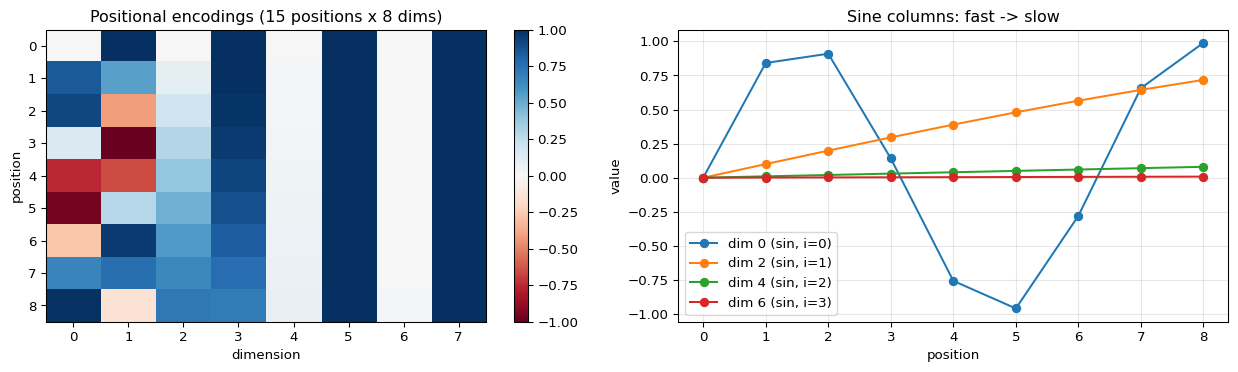

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
im = ax[0].imshow(PE_src, cmap="RdBu", aspect="auto", vmin=-1, vmax=1)
ax[0].set(title="Positional encodings (15 positions x 8 dims)",
          xlabel="dimension", ylabel="position")
plt.colorbar(im, ax=ax[0])
for d in [0, 2, 4, 6]:
    ax[1].plot(PE_src[:, d], marker="o", label=f"dim {d} (sin, i={d//2})")
ax[1].set(title="Sine columns: fast -> slow", xlabel="position", ylabel="value")
ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

### Encoder Input

$$X_{enc} = \mathrm{Embedding}(\text{src\_ids}) \cdot \sqrt{d_{model}} + PE$$

This is the step that was **missing** in the old notebook. Its effect is visible immediately: the two occurrences of `"the"` (positions 0 and 4 of the prefix), which had identical embeddings, now have different input vectors.

In [9]:
X_enc = src_emb + PE_src          # (9, 8)

print(f"X_enc shape: {X_enc.shape}\n")
for j, (w, v) in enumerate(zip(src_tokens, X_enc)):
    print(f"  {j:>2} {w:<9} {np.round(v, 3)}")

print(f"\n'the' at position 0: {np.round(X_enc[0], 3)}")
print(f"'the' at position 4: {np.round(X_enc[4], 3)}")
print(f"identical now? {np.allclose(X_enc[0], X_enc[4])}  <- order information is now present")

X_enc shape: (9, 8)

   0 the       [-0.1    0.796 -0.878  0.173 -0.226  1.367  0.914  0.197]
   1 cat       [ 0.157  1.331 -1.87   1.888 -1.201  1.731  0.015  0.046]
   2 sat       [ 2.302  0.423  1.071  0.014 -0.059  0.699 -1.004  1.36 ]
   3 on        [ 1.362 -1.867  2.008 -0.792  0.465  1.475 -0.793  1.424]
   4 the       [-0.857 -0.857 -0.489  0.094 -0.186  1.367  0.918  0.197]
   5 mat       [-0.725  1.319 -0.357  2.302 -0.042  0.111  1.003  0.713]
   6 and       [-0.815 -0.747 -0.552  2.061 -0.096  0.45   0.166  1.502]
   7 was       [-0.207  2.033  1.686  1.348 -0.06   1.577 -0.7    1.856]
   8 looking   [ 1.223 -0.394  1.918  0.837 -1.887 -0.12  -0.178  1.31 ]

'the' at position 0: [-0.1    0.796 -0.878  0.173 -0.226  1.367  0.914  0.197]
'the' at position 4: [-0.857 -0.857 -0.489  0.094 -0.186  1.367  0.918  0.197]
identical now? False  <- order information is now present


### Embeddings + Positional Encoding

$X_{enc} = \text{scaled embeddings} + PE$ is **element-wise**: three matrices of shape $(9, 8)$, nothing mixes across rows or columns. Both operands are printed side by side below.

In [10]:
show_elementwise(src_emb, PE_src, X_enc,
                 "emb*sqrt(d)", "PE", "X_enc", "+", rows=src_tokens)

  X_enc = emb*sqrt(d) + PE      all three are (9, 8) — element-wise, no mixing

       the | 
      emb*sqrt(d):   -0.100    -0.204    -0.878    -0.827    -0.226    +0.367    +0.914    -0.803
               PE:   +0.000    +1.000    +0.000    +1.000    +0.000    +1.000    +0.000    +1.000
            X_enc:   -0.100    +0.796    -0.878    +0.173    -0.226    +1.367    +0.914    +0.197

       cat | 
      emb*sqrt(d):   -0.685    +0.791    -1.970    +0.893    -1.211    +0.731    +0.014    -0.954
               PE:   +0.841    +0.540    +0.100    +0.995    +0.010    +1.000    +0.001    +1.000
            X_enc:   +0.157    +1.331    -1.870    +1.888    -1.201    +1.731    +0.015    +0.046

       sat | 
      emb*sqrt(d):   +1.393    +0.839    +0.873    -0.966    -0.079    -0.300    -1.006    +0.360
               PE:   +0.909    -0.416    +0.199    +0.980    +0.020    +1.000    +0.002    +1.000
            X_enc:   +2.302    +0.423    +1.071    +0.014    -0.059    +0.699    -1.004    +

---
# 6. Layer Normalization

This is the component whose absence caused the 80 000-magnitude output in the old notebook. For **each row** (each token) independently:

$$\mu = \frac{1}{d}\sum_{j=1}^{d} x_j, \qquad
\sigma^2 = \frac{1}{d}\sum_{j=1}^{d}(x_j - \mu)^2, \qquad
\mathrm{LN}(x) = \gamma \odot \frac{x - \mu}{\sqrt{\sigma^2 + \epsilon}} + \beta$$

Three points worth being precise about:

1. **Per row, not per column.** Unlike BatchNorm, no statistic is shared across tokens. Token $i$ is normalized using only its own 8 numbers. This is what makes it valid at inference time with a single sequence.
2. $\gamma, \beta \in \mathbb{R}^{d_{model}}$ are **learned**; initialized to $\mathbf{1}$ and $\mathbf{0}$, so LayerNorm starts as pure standardization.
3. $\epsilon = 10^{-5}$ guards against division by zero.

The original paper uses **post-norm**: `LayerNorm(x + Sublayer(x))`. That is what is implemented below. (Modern implementations often use pre-norm, `x + Sublayer(LayerNorm(x))`, which trains more stably in deep stacks — but post-norm is the 2017 architecture and this notebook follows it.)

In [11]:
def layer_norm(x, gamma, beta, eps=1e-5):
    mu  = x.mean(axis=-1, keepdims=True)     # per-token mean
    var = x.var(axis=-1, keepdims=True)      # per-token variance
    return gamma * (x - mu) / np.sqrt(var + eps) + beta

def ln_params(d=D_MODEL):
    return np.ones(d), np.zeros(d)           # gamma=1, beta=0

# Demonstration on the first token of X_enc
row = X_enc[0]
mu, var = row.mean(), row.var()
print(f"x        = {np.round(row, 3)}")
print(f"mean     = {mu:.4f}")
print(f"variance = {var:.4f}   (std = {np.sqrt(var):.4f})")
g, b = ln_params()
print(f"LN(x)    = {np.round(layer_norm(row, g, b), 3)}")
print(f"           mean = {layer_norm(row, g, b).mean():.2e}, std = {layer_norm(row, g, b).std():.4f}")

x        = [-0.1    0.796 -0.878  0.173 -0.226  1.367  0.914  0.197]
mean     = 0.2803
variance = 0.4513   (std = 0.6718)
LN(x)    = [-0.566  0.768 -1.724 -0.16  -0.754  1.618  0.943 -0.124]
           mean = -8.33e-17, std = 1.0000


---
# 7. Scaled Dot-Product Attention

$$\mathrm{Attention}(Q, K, V) = \mathrm{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}} + M\right) V$$

Reading it as a sequence of shapes, with $n_q$ queries and $n_{kv}$ keys/values:

| Step | Operation | Shape |
|---|---|---|
| 1 | $Q$, $K$, $V$ | $(n_q, d_k)$, $(n_{kv}, d_k)$, $(n_{kv}, d_v)$ |
| 2 | $S = QK^\top$ | $(n_q, n_{kv})$ — one score per (query, key) pair |
| 3 | $S / \sqrt{d_k}$ | same |
| 4 | $+ M$ (mask, optional) | same |
| 5 | $A = \mathrm{softmax}(\cdot)$ row-wise | same, **each row sums to 1** |
| 6 | $AV$ | $(n_q, d_v)$ |

**Why divide by $\sqrt{d_k}$?** If the components of $q$ and $k$ are independent with mean 0 and variance 1, then $q \cdot k = \sum_{j=1}^{d_k} q_j k_j$ has mean 0 and variance $d_k$, i.e. standard deviation $\sqrt{d_k}$. Feeding scores of that magnitude into a softmax pushes it toward a one-hot distribution, where the gradient is nearly zero. Dividing by $\sqrt{d_k}$ restores unit variance and keeps the softmax in its responsive region. Here $\sqrt{d_k} = \sqrt{4} = 2$.

**Softmax**, applied to each row $s$ independently:

$$A_{ij} = \frac{\exp(s_{ij})}{\sum_{j'} \exp(s_{ij'})}$$

implemented as `exp(s - max(s))` for numerical stability — subtracting the row max changes nothing mathematically (the constant cancels) but prevents `exp` from overflowing.

In [12]:
def softmax(x, axis=-1):
    x = x - np.max(x, axis=axis, keepdims=True)   # stability shift
    e = np.exp(x)
    return e / np.sum(e, axis=axis, keepdims=True)

def scaled_dot_product_attention(Q, K, V, mask=None):
    # Q:(..., n_q, d_k)   K,V:(..., n_kv, d_k)   mask:(n_q, n_kv) boolean, True = block
    d_k = Q.shape[-1]
    scores = Q @ np.swapaxes(K, -1, -2) / np.sqrt(d_k)
    if mask is not None:
        scores = np.where(mask, -1e9, scores)     # -1e9 instead of -inf: avoids 0*inf = NaN
    weights = softmax(scores, axis=-1)
    return weights @ V, weights, scores

print("Numerical check on a tiny example:")
q = np.array([[1.0, 0.0, 1.0, 0.0]])
k = np.array([[1.0, 0.0, 1.0, 0.0],
              [0.0, 1.0, 0.0, 1.0],
              [1.0, 1.0, 0.0, 0.0]])
v = np.array([[10.0, 0.0, 0.0, 0.0],
              [0.0, 10.0, 0.0, 0.0],
              [0.0, 0.0, 10.0, 0.0]])
out, w, s = scaled_dot_product_attention(q, k, v)
print(f"  raw scores q.k    = {np.round(q @ k.T, 3)}      (2, 0, 1)")
print(f"  scaled by sqrt(4) = {np.round(s, 3)}")
print(f"  softmax weights   = {np.round(w, 4)}  sum = {w.sum():.4f}")
print(f"  output = w @ V    = {np.round(out, 3)}")
print("  -> the query matches key 0 most, so V row 0 dominates the output.")

Numerical check on a tiny example:
  raw scores q.k    = [[2. 0. 1.]]      (2, 0, 1)
  scaled by sqrt(4) = [[1.  0.  0.5]]
  softmax weights   = [[0.506 0.186 0.307]]  sum = 1.0000
  output = w @ V    = [[5.065 1.863 3.072 0.   ]]
  -> the query matches key 0 most, so V row 0 dominates the output.


---
# 8. Multi-Head Attention

The old notebook described "multi-head" but computed a single head and omitted the output projection $W^O$. Both are corrected here.

$$\mathrm{MultiHead}(Q,K,V) = \mathrm{Concat}(\mathrm{head}_1, \dots, \mathrm{head}_h)\,W^O,
\qquad \mathrm{head}_i = \mathrm{Attention}(QW_i^Q,\, KW_i^K,\, VW_i^V)$$

**Why several heads?** A single softmax row is a probability distribution — it can only express *one* weighting of the context. Averaging cancels competing patterns. With $h$ heads, each head runs the same operation in its own $d_k$-dimensional subspace, so one head can track syntactic agreement while another tracks a co-reference, and $W^O$ recombines them.

**Implementation.** Rather than $h$ separate small matrices, one uses full $d_{model} \times d_{model}$ matrices $W^Q, W^K, W^V$ and *reshapes* the result — mathematically identical, since a block of columns of $W^Q$ is exactly $W_i^Q$:

```
X (n, 8) @ Wq (8, 8) -> Q (n, 8)
             reshape -> (n, 2, 4)
           transpose -> (2, n, 4)      # (heads, tokens, d_k)
```

Total parameter count is unchanged: $h \cdot d_k = d_{model}$. Multi-head attention costs the same as single-head, but is strictly more expressive.

In [13]:
def split_heads(x, h=N_HEADS):
    n, d = x.shape
    return x.reshape(n, h, d // h).transpose(1, 0, 2)     # (h, n, d_k)

def merge_heads(x):
    h, n, d_k = x.shape
    return x.transpose(1, 0, 2).reshape(n, h * d_k)       # (n, d_model)

class MHA:
    # Holds one attention sub-layer's four weight matrices
    def __init__(self, d_model=D_MODEL, h=N_HEADS, name=""):
        self.h, self.name = h, name
        self.Wq = xavier(d_model, d_model)
        self.Wk = xavier(d_model, d_model)
        self.Wv = xavier(d_model, d_model)
        self.Wo = xavier(d_model, d_model)

    def __call__(self, x_q, x_kv, mask=None, verbose=False):
        Q = split_heads(x_q  @ self.Wq, self.h)    # (h, n_q,  d_k)
        K = split_heads(x_kv @ self.Wk, self.h)    # (h, n_kv, d_k)
        V = split_heads(x_kv @ self.Wv, self.h)    # (h, n_kv, d_v)
        head_out, weights, scores = scaled_dot_product_attention(Q, K, V, mask)
        concat = merge_heads(head_out)             # (n_q, d_model)
        out = concat @ self.Wo                     # (n_q, d_model)
        if verbose:
            print(f"[{self.name}] x_q {x_q.shape} , x_kv {x_kv.shape}")
            print(f"  Q,K,V per head: {Q.shape}, {K.shape}, {V.shape}")
            print(f"  scores/weights: {weights.shape}   concat: {concat.shape}   out: {out.shape}")
        return out, weights, scores, (Q, K, V, concat)

print("MHA class defined. Each instance owns Wq, Wk, Wv, Wo of shape (8, 8).")
print(f"Parameters per attention sub-layer: 4 * 8 * 8 = {4*8*8}")

MHA class defined. Each instance owns Wq, Wk, Wv, Wo of shape (8, 8).
Parameters per attention sub-layer: 4 * 8 * 8 = 256


---
# 9. Encoder: Self-Attention

"Self"-attention means $Q$, $K$ and $V$ all come from the **same** input $X_{enc}$. **No causal mask is used here.** This is the point that most often causes confusion in an autoregressive setup: the *prefix* is fully known input, not something being generated, so the encoder is free to be **bidirectional** — token 2 may look at token 7. The autoregressive constraint applies only to the decoder side, where tokens are produced one at a time.

Below the computation is unrolled, and one score is verified by hand against the definition.

In [14]:
enc_self = MHA(name="encoder self-attn")

enc_attn_out, enc_w, enc_scores, (Qe, Ke, Ve, concat_e) = enc_self(
    X_enc, X_enc, mask=None, verbose=True)

print(f"\n--- Head 0: Q, K, V ({X_enc.shape[0]} x {D_K} each) ---")
print(f"Q[head0]:\n{np.round(Qe[0], 3)}")
print(f"\nK[head0]:\n{np.round(Ke[0], 3)}")
print(f"\nV[head0]:\n{np.round(Ve[0], 3)}")

print(f"\n--- Head 0: raw scores Q K^T / sqrt(d_k), shape {enc_scores[0].shape} ---")
print(np.round(enc_scores[0], 3))

[encoder self-attn] x_q (9, 8) , x_kv (9, 8)
  Q,K,V per head: (2, 9, 4), (2, 9, 4), (2, 9, 4)
  scores/weights: (2, 9, 9)   concat: (9, 8)   out: (9, 8)

--- Head 0: Q, K, V (9 x 4 each) ---
Q[head0]:
[[-0.363  0.43   1.132 -1.267]
 [-1.14  -1.112  0.583 -0.527]
 [-0.04  -0.869  0.345 -0.223]
 [ 1.895  1.278  0.877  0.181]
 [ 0.557  1.335  1.018 -0.361]
 [-1.574  0.05  -0.869 -0.623]
 [-0.513  0.355 -0.385  0.953]
 [ 0.287  0.698 -0.771 -1.189]
 [-0.319 -0.98  -0.91   1.053]]

K[head0]:
[[-0.642  0.947 -0.654 -0.265]
 [-0.815  1.333 -0.331  0.315]
 [-0.212  0.556  1.075  0.39 ]
 [ 0.833 -0.997  1.658 -0.011]
 [ 0.126 -0.482  0.012 -0.353]
 [ 0.888 -0.151  0.471 -0.344]
 [ 1.368 -1.584  1.217 -0.221]
 [ 1.429 -0.377  0.183  0.313]
 [ 0.161 -1.964  2.485  1.113]]

V[head0]:
[[-1.375 -1.282  0.058  1.186]
 [-2.807 -1.31  -0.778  1.31 ]
 [ 0.743  0.139 -0.711 -1.884]
 [ 1.641 -0.434  0.404 -0.671]
 [-1.132 -1.533  0.746  2.018]
 [-3.082 -0.455 -1.491  0.839]
 [-2.619 -1.071 -0.747  1.683]

In [15]:
# Hand-verification of one attention score: head 0, query = token 1 ('cat'), key = token 8 ('looking')
i, j, head = 1, 8, 0
manual_dot = float(np.dot(Qe[head, i], Ke[head, j]))
manual_scaled = manual_dot / np.sqrt(D_K)

print(f"q_1 (head 0, token '{src_tokens[i]}') = {np.round(Qe[head, i], 4)}")
print(f"k_{j} (head 0, token '{src_tokens[j]}') = {np.round(Ke[head, j], 4)}")
print(f"\nq . k  = " + " + ".join(f"({a:.4f})({b:.4f})"
      for a, b in zip(Qe[head, i], Ke[head, j])))
print(f"       = {manual_dot:.6f}")
print(f"/ sqrt(d_k) = {manual_dot:.6f} / {np.sqrt(D_K):.1f} = {manual_scaled:.6f}")
print(f"\nFrom the scores matrix: {enc_scores[head, i, j]:.6f}   match: "
      f"{np.isclose(manual_scaled, enc_scores[head, i, j])}")

# And the softmax of that row, by hand
row = enc_scores[head, i]
e = np.exp(row - row.max())
manual_row = e / e.sum()
print(f"\nSoftmax of row {i} (head 0), by hand:\n{np.round(manual_row, 4)}")
print(f"sum = {manual_row.sum():.6f}")
print(f"matches library row: {np.allclose(manual_row, enc_w[head, i])}")

q_1 (head 0, token 'cat') = [-1.14  -1.112  0.583 -0.527]
k_8 (head 0, token 'looking') = [ 0.161 -1.964  2.485  1.113]

q . k  = (-1.1400)(0.1606) + (-1.1117)(-1.9641) + (0.5834)(2.4849) + (-0.5266)(1.1127)
       = 2.864096
/ sqrt(d_k) = 2.864096 / 2.0 = 1.432048

From the scores matrix: 1.432048   match: True

Softmax of row 1 (head 0), by hand:
[0.059 0.05  0.08  0.138 0.105 0.065 0.131 0.042 0.329]
sum = 1.000000
matches library row: True


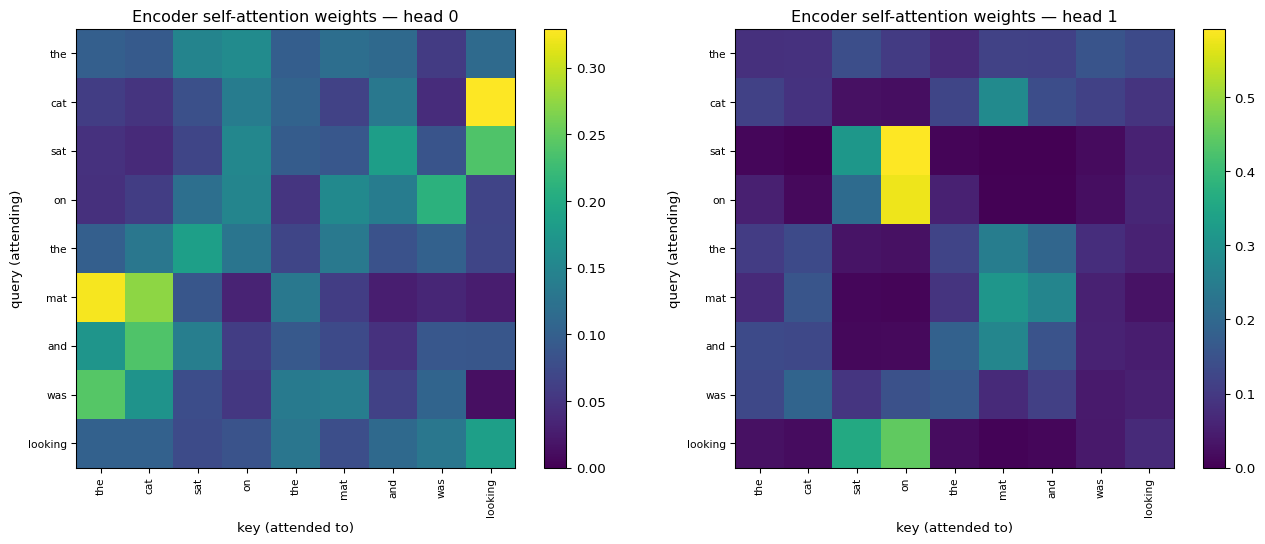

Every row sums to 1: True

Note the full square (no mask): the encoder is bidirectional over the prefix.
The pattern is diffuse because the weights are random, not trained.


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for hh in range(N_HEADS):
    im = axes[hh].imshow(enc_w[hh], cmap="viridis", vmin=0)
    axes[hh].set(title=f"Encoder self-attention weights — head {hh}",
                 xlabel="key (attended to)", ylabel="query (attending)")
    axes[hh].set_xticks(range(len(src_tokens)), src_tokens, rotation=90, fontsize=8)
    axes[hh].set_yticks(range(len(src_tokens)), src_tokens, fontsize=8)
    plt.colorbar(im, ax=axes[hh])
plt.tight_layout(); plt.show()

print("Every row sums to 1:", np.allclose(enc_w.sum(axis=-1), 1.0))
print("\nNote the full square (no mask): the encoder is bidirectional over the prefix.")
print("The pattern is diffuse because the weights are random, not trained.")

---
### Self-Attention, Step by Step

This is the shape question spelled out. Follow the inner dimensions as they cancel:

| # | operation | shapes | result |
|---|---|---|---|
| 1 | $X_{enc} W^Q$ | $(9,8) @ (8,8)$ | $(9,8)$ |
| 2 | split into heads | reshape | $(2,9,4)$ |
| 3 | $Q_0 K_0^\top$ | $(9,4) @ (4,9)$ | $(9,\mathbf{9})$ |
| 4 | softmax | element-wise per row | $(9,9)$ |
| 5 | $A V_0$ | $(9,9) @ (9,4)$ | $(9,\mathbf{4})$ |
| 6 | concat heads | $(9,4) + (9,4)$ side by side | $(9,8)$ |
| 7 | $\cdot\, W^O$ | $(9,8) @ (8,8)$ | $(9,8)$ |

**Why step 5 returns $(9,4)$ and not $(9,9)$:** the $9 \times 9$ matrix is *weights*, not content. In $AV$ the shared dimension is the 9 **keys**, and it cancels — $(9,9)@(9,4) \to (9,4)$. Each output row is a weighted average of the 9 rows of $V$, so it has $V$'s width, which is $d_v = 4$. The count of tokens sets the number of *rows*, never the number of columns.

The block therefore returns $(9,8)$ — exactly the shape it received. That invariance is what allows 6 blocks to be stacked.

In [17]:
# ---- STEP 1 : project X_enc to Q (K and V are identical in form) ----
print("STEP 1 : project X_enc to Q (K and V are identical in form)")
print("=" * 78)
Q_full = X_enc @ enc_self.Wq
show_matmul(X_enc, enc_self.Wq, Q_full, "X_enc", "Wq", "Q_full",
            rows_A=src_tokens, note="K uses Wk, V uses Wv — same shapes, same arithmetic")

K_full = X_enc @ enc_self.Wk
V_full = X_enc @ enc_self.Wv
print(f"\nK_full = X_enc @ Wk -> {K_full.shape}")
print(f"V_full = X_enc @ Wv -> {V_full.shape}")

STEP 1 : project X_enc to Q (K and V are identical in form)
  X_enc (9, 8)   @   Wq (8, 8)   =   Q_full (9, 8)
  shape rule: (9 x 8) @ (8 x 8) -> (9 x 8)   inner dim 8 cancels
  K uses Wk, V uses Wv — same shapes, same arithmetic

X_enc =
          the |   -0.100    +0.796    -0.878    +0.173    -0.226    +1.367    +0.914    +0.197
          cat |   +0.157    +1.331    -1.870    +1.888    -1.201    +1.731    +0.015    +0.046
          sat |   +2.302    +0.423    +1.071    +0.014    -0.059    +0.699    -1.004    +1.360
           on |   +1.362    -1.867    +2.008    -0.792    +0.465    +1.475    -0.793    +1.424
          the |   -0.857    -0.857    -0.489    +0.094    -0.186    +1.367    +0.918    +0.197
          mat |   -0.725    +1.319    -0.357    +2.302    -0.042    +0.111    +1.003    +0.713
          and |   -0.815    -0.747    -0.552    +2.061    -0.096    +0.450    +0.166    +1.502
          was |   -0.207    +2.033    +1.686    +1.348    -0.060    +1.577    -0.700    +1.856
 

In [18]:
# ---- STEP 2 : split the 8 columns into 2 heads of 4 ----
print("STEP 2 : split the 8 columns into 2 heads of 4")
print("=" * 78)
print(f"Q_full {Q_full.shape}  ->  reshape(9, 2, 4)  ->  transpose  ->  (2, 9, 4)\n")
print(f"head 0 takes columns 0..3, head 1 takes columns 4..7\n")
print(f"Q head 0 {Qe[0].shape}:\n{np.round(Qe[0], 3)}")
print(f"\nQ head 1 {Qe[1].shape}:\n{np.round(Qe[1], 3)}")
print(f"\nmatches the column slices of Q_full: "
      f"{np.allclose(Qe[0], Q_full[:, :4]) and np.allclose(Qe[1], Q_full[:, 4:])}")

STEP 2 : split the 8 columns into 2 heads of 4
Q_full (9, 8)  ->  reshape(9, 2, 4)  ->  transpose  ->  (2, 9, 4)

head 0 takes columns 0..3, head 1 takes columns 4..7

Q head 0 (9, 4):
[[-0.363  0.43   1.132 -1.267]
 [-1.14  -1.112  0.583 -0.527]
 [-0.04  -0.869  0.345 -0.223]
 [ 1.895  1.278  0.877  0.181]
 [ 0.557  1.335  1.018 -0.361]
 [-1.574  0.05  -0.869 -0.623]
 [-0.513  0.355 -0.385  0.953]
 [ 0.287  0.698 -0.771 -1.189]
 [-0.319 -0.98  -0.91   1.053]]

Q head 1 (9, 4):
[[ 0.149 -0.034 -0.191 -0.764]
 [-0.22   1.32   0.033 -0.87 ]
 [ 1.661 -0.113 -1.033  2.714]
 [ 1.397  0.233  0.047  3.064]
 [-0.263  0.392  0.511 -0.763]
 [-1.129  0.147  0.361 -1.317]
 [-0.637  1.16   0.4   -0.138]
 [-0.113 -0.821  0.7    1.169]
 [ 0.767 -1.128 -0.522  1.422]]

matches the column slices of Q_full: True


In [19]:
# ---- STEP 3 : scores = Q0 @ K0^T, THEN divide by sqrt(d_k) ----
print("STEP 3 : scores = Q0 @ K0^T, THEN divide by sqrt(d_k)")
print("=" * 78)
raw_scores = Qe[0] @ Ke[0].T
show_matmul(Qe[0], Ke[0].T, raw_scores, "Q_head0", "K_head0^T", "raw_scores",
            rows_A=src_tokens,
            note="K is TRANSPOSED: (9,4) becomes (4,9) so the inner dim 4 can cancel")

print(f"\nthen divide every entry by sqrt(d_k) = sqrt(4) = 2:")
print(np.round(raw_scores / 2, 3))
print(f"\nmatches enc_scores[0]: {np.allclose(raw_scores / 2, enc_scores[0])}")
print(f"\n>>> this (9, 9) matrix is WEIGHTS, not output. 9 queries x 9 keys.")

STEP 3 : scores = Q0 @ K0^T, THEN divide by sqrt(d_k)
  Q_head0 (9, 4)   @   K_head0^T (4, 9)   =   raw_scores (9, 9)
  shape rule: (9 x 4) @ (4 x 9) -> (9 x 9)   inner dim 4 cancels
  K is TRANSPOSED: (9,4) becomes (4,9) so the inner dim 4 can cancel

Q_head0 =
          the |   -0.363    +0.430    +1.132    -1.267
          cat |   -1.140    -1.112    +0.583    -0.527
          sat |   -0.040    -0.869    +0.345    -0.223
           on |   +1.895    +1.278    +0.877    +0.181
          the |   +0.557    +1.335    +1.018    -0.361
          mat |   -1.574    +0.050    -0.869    -0.623
          and |   -0.513    +0.355    -0.385    +0.953
          was |   +0.287    +0.698    -0.771    -1.189
      looking |   -0.319    -0.980    -0.910    +1.053

K_head0^T =
     -0.642    -0.815    -0.212    +0.833    +0.126    +0.888    +1.368    +1.429    +0.161
     +0.947    +1.333    +0.556    -0.997    -0.482    -0.151    -1.584    -0.377    -1.964
     -0.654    -0.331    +1.075    +1.658    

In [20]:
# ---- STEP 5 : the multiplication that answers the shape question ----
print("STEP 5 : the multiplication that answers the shape question")
print("=" * 78)
head0_out = enc_w[0] @ Ve[0]
show_matmul(enc_w[0], Ve[0], head0_out, "A (weights)", "V_head0", "head0_out",
            rows_A=src_tokens,
            note="the 9 KEYS are the shared dimension and cancel: (9,9)@(9,4) -> (9,4)")

print(f"\n>>> (9, 9) @ (9, 4) = (9, 4).  The 9x9 collapsed back to width 4.")
print(f">>> Row i of the result is a weighted average of the 9 rows of V,")
print(f">>> so it must have V's width (d_v = 4), not the token count.")

STEP 5 : the multiplication that answers the shape question
  A (weights) (9, 9)   @   V_head0 (9, 4)   =   head0_out (9, 4)
  shape rule: (9 x 9) @ (9 x 4) -> (9 x 4)   inner dim 9 cancels
  the 9 KEYS are the shared dimension and cancel: (9,9)@(9,4) -> (9,4)

A (weights) =
          the |   +0.100    +0.093    +0.149    +0.158    +0.098    +0.119    +0.113    +0.057    +0.114
          cat |   +0.059    +0.050    +0.080    +0.138    +0.105    +0.065    +0.131    +0.042    +0.329
          sat |   +0.046    +0.039    +0.068    +0.152    +0.096    +0.089    +0.184    +0.086    +0.239
           on |   +0.045    +0.060    +0.121    +0.150    +0.050    +0.156    +0.138    +0.211    +0.068
          the |   +0.100    +0.131    +0.186    +0.128    +0.068    +0.133    +0.083    +0.102    +0.069
          mat |   +0.325    +0.273    +0.088    +0.033    +0.132    +0.060    +0.027    +0.036    +0.027
          and |   +0.172    +0.238    +0.140    +0.060    +0.092    +0.074    +0.047    +0.089

In [21]:
# ---- STEPS 6 and 7 : concatenate the heads, then project with W_O ----
print("STEPS 6 and 7 : concatenate the heads, then project with W_O")
print("=" * 78)
head1_out = enc_w[1] @ Ve[1]
concat = np.concatenate([head0_out, head1_out], axis=1)

print(f"head0_out {head0_out.shape}   +   head1_out {head1_out.shape}"
      f"   side by side   ->   concat {concat.shape}\n")
print(f"{'token':>10} | {'---- head 0 (dims 0-3) ----':^38} | {'---- head 1 (dims 4-7) ----':^38}")
print("-" * 92)
for r in range(concat.shape[0]):
    h0 = "  ".join(f"{v:+8.3f}" for v in head0_out[r])
    h1 = "  ".join(f"{v:+8.3f}" for v in head1_out[r])
    print(f"{src_tokens[r]:>10} | {h0} | {h1}")

print(f"\nmatches concat_e: {np.allclose(concat, concat_e)}\n")

show_matmul(concat, enc_self.Wo, enc_attn_out, "concat", "W_O", "attn_out",
            rows_A=src_tokens,
            note="W_O is what MIXES the two heads — without it they stay separate")

STEPS 6 and 7 : concatenate the heads, then project with W_O
head0_out (9, 4)   +   head1_out (9, 4)   side by side   ->   concat (9, 8)

     token |      ---- head 0 (dims 0-3) ----       |      ---- head 1 (dims 4-7) ----      
--------------------------------------------------------------------------------------------
       the |   -1.056    -0.609    -0.373    +0.150 |   +0.444    +0.965    +0.219    +0.641
       cat |   -1.043    -0.545    -0.128    -0.077 |   +1.377    +0.827    +0.138    +0.455
       sat |   -1.195    -0.542    -0.307    +0.081 |   -1.675    +1.218    +0.676    +0.960
        on |   -1.373    -0.387    -0.771    +0.019 |   -1.276    +1.107    +0.730    +0.920
       the |   -1.177    -0.543    -0.567    +0.075 |   +1.481    +0.723    +0.177    +0.401
       mat |   -1.611    -1.020    -0.317    +0.854 |   +1.799    +0.757    +0.101    +0.299
       and |   -1.461    -0.731    -0.478    +0.355 |   +1.617    +0.604    +0.223    +0.383
       was |   -1.678    

### Encoder Add & Norm (1)

$$X' = \mathrm{LayerNorm}\big(X_{enc} + \mathrm{MultiHead}(X_{enc})\big)$$

The residual `+` is what lets the original token identity survive an arbitrary number of layers; the LayerNorm is what keeps the magnitude from drifting. Watch the mean and standard deviation before and after.

In [22]:
g1_e, b1_e = ln_params()
enc_res1  = X_enc + enc_attn_out
enc_norm1 = layer_norm(enc_res1, g1_e, b1_e)

print(f"attention output   : mean={enc_attn_out.mean():+.4f}  std={enc_attn_out.std():.4f}")
print(f"after residual add : mean={enc_res1.mean():+.4f}  std={enc_res1.std():.4f}")
print(f"after LayerNorm    : mean={enc_norm1.mean():+.4f}  std={enc_norm1.std():.4f}   <- rescaled")
print(f"\nEncoder Add&Norm 1 output (shape {enc_norm1.shape}):\n{np.round(enc_norm1, 3)}")

attention output   : mean=+0.0581  std=0.8073
after residual add : mean=+0.4630  std=1.2245
after LayerNorm    : mean=+0.0000  std=1.0000   <- rescaled

Encoder Add&Norm 1 output (shape (9, 8)):
[[ 0.411  0.715 -1.678 -1.084  0.14   1.521  0.693 -0.718]
 [ 0.175  0.808 -1.938  0.333 -0.421  1.739 -0.288 -0.408]
 [ 2.439  0.46  -0.19  -0.744 -0.779 -0.183 -0.735 -0.268]
 [ 1.913 -0.932  0.534 -1.464 -0.105  0.682 -0.745  0.116]
 [-0.502 -0.768 -0.893 -1.211  0.82   1.975  0.565  0.014]
 [-1.366  0.494 -1.875  0.498  0.814  0.489  1.096 -0.149]
 [-0.831 -1.17  -1.532  0.369  0.84   1.15  -0.021  1.195]
 [-0.644  1.286 -0.341 -0.976 -0.26   1.483 -1.379  0.832]
 [ 1.965  0.004  0.529 -0.079 -1.908 -0.457 -0.002 -0.052]]


### Add & Norm Operands

In [23]:
show_elementwise(X_enc, enc_attn_out, enc_res1,
                 "X_enc", "attn_out", "residual", "+", rows=src_tokens)

print("\n\nThen LayerNorm, row by row (each token uses only its own 8 numbers):\n")
print(f"{'token':>10} | {'mean':>9} {'std':>9} | before -> after (dim 0..7)")
print("-" * 92)
for r in range(enc_res1.shape[0]):
    print(f"{src_tokens[r]:>10} | {enc_res1[r].mean():+9.4f} {enc_res1[r].std():9.4f} | "
          + "  ".join(f"{v:+6.2f}" for v in enc_res1[r]))
    print(f"{'':>10} | {'':>9} {'':>9} | "
          + "  ".join(f"{v:+6.2f}" for v in enc_norm1[r]) + "   <- normalized")

  residual = X_enc + attn_out      all three are (9, 8) — element-wise, no mixing

       the | 
            X_enc:   -0.100    +0.796    -0.878    +0.173    -0.226    +1.367    +0.914    +0.197
         attn_out:   +0.889    +0.304    -0.476    -0.917    +0.737    +0.560    +0.165    -0.565
         residual:   +0.789    +1.101    -1.354    -0.744    +0.511    +1.927    +1.078    -0.368

       cat | 
            X_enc:   +0.157    +1.331    -1.870    +1.888    -1.201    +1.731    +0.015    +0.046
         attn_out:   +0.298    -0.049    -0.437    -1.226    +0.878    +0.768    -0.166    -0.353
         residual:   +0.455    +1.282    -2.307    +0.662    -0.324    +2.499    -0.150    -0.307

       sat | 
            X_enc:   +2.302    +0.423    +1.071    +0.014    -0.059    +0.699    -1.004    +1.360
         attn_out:   +2.155    +1.103    -0.508    -0.271    -0.249    -0.125    +0.760    -0.912
         residual:   +4.457    +1.526    +0.563    -0.257    -0.308    +0.575    -0.243  

---
# 10. Encoder: Feed-Forward Network

$$\mathrm{FFN}(x) = \max(0,\, xW_1 + b_1)\,W_2 + b_2, \qquad
W_1 \in \mathbb{R}^{8 \times 32},\; W_2 \in \mathbb{R}^{32 \times 8}$$

"**Position-wise**" is the key word: the *same* $W_1, W_2$ are applied to each of the 15 token vectors **independently**. There is no mixing across positions here — all cross-token communication happened in the attention sub-layer. Equivalently, this is a 1-D convolution with kernel size 1.

Why widen to $d_{ff} = 4 d_{model}$ and come back? The expansion plus ReLU is what gives the block its non-linearity and its capacity; attention alone is (up to the softmax) a linear re-weighting of values. In a trained model the FFN holds the majority of the parameters.

ReLU: $\max(0, z)$ — it zeroes the negative half, and here roughly half the 32 hidden units will be inactive per token.

In [24]:
W1_e, b1f_e = xavier(D_MODEL, D_FF), np.zeros(D_FF)
W2_e, b2f_e = xavier(D_FF, D_MODEL), np.zeros(D_MODEL)

lin1_e  = enc_norm1 @ W1_e + b1f_e          # (15, 32)
relu_e  = np.maximum(0, lin1_e)             # (15, 32)
ffn_e   = relu_e @ W2_e + b2f_e             # (15, 8)

print(f"input           {enc_norm1.shape}")
print(f"@ W1 + b1    -> {lin1_e.shape}")
print(f"ReLU         -> {relu_e.shape}   ({(relu_e == 0).mean()*100:.1f}% of units zeroed)")
print(f"@ W2 + b2    -> {ffn_e.shape}\n")
print(f"FFN output:\n{np.round(ffn_e, 3)}")

# Hand check of one hidden unit
tok, unit = 0, 5
manual = float(enc_norm1[tok] @ W1_e[:, unit] + b1f_e[unit])
print(f"\nHand check, token {tok} hidden unit {unit}:")
print(f"  x . W1[:,{unit}] + b1 = {manual:.6f}  ->  ReLU = {max(0.0, manual):.6f}")
print(f"  from arrays: pre-ReLU {lin1_e[tok, unit]:.6f}, post-ReLU {relu_e[tok, unit]:.6f}")

input           (9, 8)
@ W1 + b1    -> (9, 32)
ReLU         -> (9, 32)   (47.9% of units zeroed)
@ W2 + b2    -> (9, 8)

FFN output:
[[-0.356 -0.582  0.497 -0.98  -0.271 -0.415  0.712 -0.682]
 [-0.286 -0.416  0.454 -1.062  0.248 -1.02   0.6   -1.103]
 [ 0.929 -0.895  0.363 -0.304  0.117 -0.872  0.691 -0.045]
 [ 1.508 -0.685 -0.219 -0.446 -0.421 -0.528  0.863  0.345]
 [-0.052 -0.962  0.084 -0.346  0.016 -0.607  0.336 -0.609]
 [-0.388 -0.072  0.468 -1.447 -0.708 -0.897  0.807 -0.654]
 [ 0.321 -0.755  0.363 -0.291 -0.218 -1.309  0.955 -0.376]
 [ 0.28  -0.163 -0.124  0.022  0.478 -0.853  0.423 -0.951]
 [ 0.614 -0.12  -0.11  -0.333  0.078 -0.498  0.419  0.031]]

Hand check, token 0 hidden unit 5:
  x . W1[:,5] + b1 = 0.586878  ->  ReLU = 0.586878
  from arrays: pre-ReLU 0.586878, post-ReLU 0.586878


### FFN Matrices

The requested view: the $(9,8)$ input printed next to $W_1$ $(8,32)$, so the multiplication is visible rather than implied.

In [25]:
show_matmul(enc_norm1, W1_e, lin1_e, "FFN input (9,8)", "W1 (8,32)", "pre-ReLU (9,32)",
            rows_A=src_tokens,
            note="each of the 9 tokens is expanded from 8 to 32 dims, independently")

print(f"\n\nReLU zeroes every negative entry — {(relu_e == 0).sum()} of "
      f"{relu_e.size} entries ({(relu_e == 0).mean()*100:.1f}%):\n")
print(f"{'token':>10} | {'negatives killed':>17} | first 12 units after ReLU")
print("-" * 88)
for r in range(relu_e.shape[0]):
    print(f"{src_tokens[r]:>10} | {int((relu_e[r] == 0).sum()):>17} | "
          + "  ".join(f"{v:5.2f}" for v in relu_e[r][:12]))

  FFN input (9,8) (9, 8)   @   W1 (8,32) (8, 32)   =   pre-ReLU (9,32) (9, 32)
  shape rule: (9 x 8) @ (8 x 32) -> (9 x 32)   inner dim 8 cancels
  each of the 9 tokens is expanded from 8 to 32 dims, independently

FFN input (9,8) =
          the |   +0.411    +0.715    -1.678    -1.084    +0.140    +1.521    +0.693    -0.718
          cat |   +0.175    +0.808    -1.938    +0.333    -0.421    +1.739    -0.288    -0.408
          sat |   +2.439    +0.460    -0.190    -0.744    -0.779    -0.183    -0.735    -0.268
           on |   +1.913    -0.932    +0.534    -1.464    -0.105    +0.682    -0.745    +0.116
          the |   -0.502    -0.768    -0.893    -1.211    +0.820    +1.975    +0.565    +0.014
          mat |   -1.366    +0.494    -1.875    +0.498    +0.814    +0.489    +1.096    -0.149
          and |   -0.831    -1.170    -1.532    +0.369    +0.840    +1.150    -0.021    +1.195
          was |   -0.644    +1.286    -0.341    -0.976    -0.260    +1.483    -1.379    +0.832
      l

In [26]:
show_matmul(relu_e, W2_e, ffn_e, "post-ReLU (9,32)", "W2 (32,8)", "FFN out (9,8)",
            rows_A=src_tokens,
            note="contraction back to d_model: each output element sums 32 products")

print("\n\nFinal Add & Norm of the encoder:")
show_elementwise(enc_norm1, ffn_e, enc_norm1 + ffn_e,
                 "LN1 out", "FFN out", "residual", "+", rows=src_tokens)
_H = layer_norm(enc_norm1 + ffn_e, np.ones(D_MODEL), np.zeros(D_MODEL))
print(f"\nAfter LayerNorm -> encoder_output H {_H.shape}:")
print(np.round(_H, 3))
print("\n(the next cell assigns this to `encoder_output`)")

  post-ReLU (9,32) (9, 32)   @   W2 (32,8) (32, 8)   =   FFN out (9,8) (9, 8)
  shape rule: (9 x 32) @ (32 x 8) -> (9 x 8)   inner dim 32 cancels
  contraction back to d_model: each output element sums 32 products

post-ReLU (9,32) =   [showing first 12 of 32 columns]
          the |   +0.000    +0.688    +0.000    +1.056    +0.000    +0.587    +0.000    +0.000    +0.713    +0.000    +0.626    +0.000
          cat |   +0.000    +0.753    +0.000    +0.287    +0.000    +0.808    +0.087    +0.000    +1.225    +0.000    +0.605    +0.000
          sat |   +0.627    +0.000    +0.000    +0.147    +0.000    +0.000    +0.000    +0.557    +1.142    +0.000    +0.870    +0.000
           on |   +0.210    +0.000    +0.000    +0.000    +0.000    +0.000    +0.000    +1.262    +0.000    +0.000    +1.118    +0.000
          the |   +0.000    +0.668    +0.000    +0.470    +0.000    +0.412    +0.000    +0.065    +0.000    +0.000    +0.597    +0.024
          mat |   +0.000    +0.950    +0.413    +0.641  

### Encoder Add & Norm (2)

$$\text{encoder\_output} = \mathrm{LayerNorm}\big(X' + \mathrm{FFN}(X')\big)$$

This $(9 \times 8)$ matrix, call it $H$, is the **memory** the decoder will read from through cross-attention. It is computed **once** and reused at every generation step. In a real model, $N = 6$ such blocks are stacked; here one block is enough to see the mechanics.

In [27]:
g2_e, b2_e = ln_params()
encoder_output = layer_norm(enc_norm1 + ffn_e, g2_e, b2_e)

print(f"ENCODER OUTPUT  H  (shape {encoder_output.shape}):\n{np.round(encoder_output, 3)}\n")
print(f"mean = {encoder_output.mean():+.4f},  std = {encoder_output.std():.4f}")
print(f"per-row std (should all be ~1 after LN): {np.round(encoder_output.std(axis=1), 3)}")
print(f"\nCompare with the old notebook, where the equivalent matrix had "
      f"values around 80 000 and near-identical rows.")
print(f"Row-to-row spread here: {encoder_output.std(axis=0).mean():.4f}  "
      f"(tokens remain distinguishable)")

ENCODER OUTPUT  H  (shape (9, 8)):
[[ 0.277  0.346 -0.812 -1.589  0.113  1.203  1.466 -1.004]
 [ 0.268  0.905 -1.47  -0.513  0.191  1.319  0.803 -1.504]
 [ 2.52  -0.324  0.131 -0.782 -0.493 -0.787 -0.031 -0.233]
 [ 2.211 -1.096  0.173 -1.288 -0.379  0.067  0.044  0.268]
 [-0.262 -1.339 -0.496 -1.181  1.01   1.498  1.07  -0.3  ]
 [-1.276  0.717 -0.958 -0.538  0.428 -0.042  2.074 -0.405]
 [-0.368 -1.872 -1.069  0.257  0.835  0.004  1.167  1.045]
 [-0.368  1.791 -0.514 -1.225  0.478  1.076 -1.227 -0.011]
 [ 2.148 -0.105  0.342 -0.353 -1.538 -0.807  0.34  -0.026]]

mean = -0.0000,  std = 1.0000
per-row std (should all be ~1 after LN): [1. 1. 1. 1. 1. 1. 1. 1. 1.]

Compare with the old notebook, where the equivalent matrix had values around 80 000 and near-identical rows.
Row-to-row spread here: 0.8410  (tokens remain distinguishable)


---
# 11. Decoder Input: Shift Right

This is the second bug from the old notebook (`X_decoder_input = X`). The decoder must **not** receive the prefix, and it must **not** receive the continuation unshifted.

The continuation is fed **shifted right by one**, with `<sos>` prepended:

| position $t$ | 0 | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|---|
| **input** (shifted) | `<sos>` | at | a | tiny | mouse | running | by |
| **label** (to predict) | at | a | tiny | mouse | running | by | `<eos>` |

So at every position the decoder predicts the token **one step to the right** of its own input. This is exactly the autoregressive factorization

$$P(y_t \mid y_{<t},\, x)$$

written as a table.

**Teacher forcing.** During training the *correct* previous tokens are supplied rather than the model's own guesses, which lets all 7 positions be computed in a single parallel pass instead of 7 sequential ones. At inference time the true continuation does not exist, so the loop of section 19 feeds back the model's own predictions instead.

Combined with the causal mask (next section), the invariant is: *the prediction at position $t$ depends only on the prefix $x$ and on continuation tokens $0 \dots t$ — never on $t+1$*. Without the shift, or without the mask, the model could read the answer and the task would be trivial.

In [28]:
dec_input_ids = np.concatenate([[SOS_ID], tgt_ids])          # <sos> + the 6 continuation tokens
labels        = np.concatenate([tgt_ids, [EOS_ID]])           # the 6 continuation tokens + <eos>
n_tgt         = len(dec_input_ids)
n_src         = len(src_ids)

print(f"n_src = {n_src},  n_tgt = {n_tgt}\n")
print(f"PREFIX (encoder): {' '.join(src_tokens)}\n")
print(f"{'pos':>3}  {'decoder input':<12} {'id':>4}   ->   {'label (predict)':<15} {'id':>4}")
print("-" * 62)
for t in range(n_tgt):
    print(f"{t:>3}  {id2word[dec_input_ids[t]]:<12} {dec_input_ids[t]:>4}   ->   "
          f"{id2word[labels[t]]:<15} {labels[t]:>4}")

PE_tgt  = positional_encoding(n_tgt, D_MODEL)
X_dec   = E[dec_input_ids] * scale + PE_tgt                    # (11, 8)
print(f"\nX_dec = E[dec_input_ids] * sqrt(d_model) + PE   shape {X_dec.shape}")
print(np.round(X_dec, 3))

n_src = 9,  n_tgt = 7

PREFIX (encoder): the cat sat on the mat and was looking

pos  decoder input   id   ->   label (predict)   id
--------------------------------------------------------------
  0  <sos>           1   ->   at               127
  1  at            127   ->   a                340
  2  a             340   ->   tiny              68
  3  tiny           68   ->   mouse             57
  4  mouse          57   ->   running          412
  5  running       412   ->   by               322
  6  by            322   ->   <eos>              2

X_dec = E[dec_input_ids] * sqrt(d_model) + PE   shape (7, 8)
[[ 1.382  1.649 -0.167  1.147  1.207  0.183  0.369  0.607]
 [ 2.015  0.91  -0.007  1.443 -1.561 -0.127 -1.193  1.143]
 [ 0.129  0.666 -1.151  0.565  0.054  1.111 -0.177  1.396]
 [ 0.449 -0.174  1.156  0.372 -0.137  1.282 -0.246  2.607]
 [-0.32   0.537  1.339 -0.564 -2.514  1.934 -1.363  0.775]
 [-1.805 -0.301  0.001  1.237  2.399  0.283 -0.412  0.937]
 [-0.123  1.984  0.74  -0.511 -

---
# 12. Decoder: Masked Self-Attention

Same operation as encoder self-attention, plus a **look-ahead mask** applied to the scores *before* the softmax:

$$M_{ij} = \begin{cases} 0 & j \le i \quad \text{(past and present: allowed)} \\[2pt] -\infty & j > i \quad \text{(future: blocked)} \end{cases}$$

$$A = \mathrm{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}} + M\right)$$

The mechanism: $\exp(-\infty) = 0$, so a blocked entry contributes 0 to both the numerator and the denominator of the softmax. The row still sums to 1 — the probability mass is simply redistributed over the allowed positions.

In code `-1e9` is used rather than `-np.inf`. This matters: with `-inf`, a fully-masked row would produce `0/0 = NaN`, and `0 * inf` appears in some autograd paths. `-1e9` is numerically indistinguishable after `exp` (it underflows to exactly 0 in float64) and is safe.

Consequences visible below:

* Row 0 (`<sos>`) attends **only to itself** → weight exactly 1.0, all others 0.
* Row $t$ has exactly $t+1$ non-zero entries.
* The weight matrix is **lower-triangular**.

In [29]:
causal_mask = np.triu(np.ones((n_tgt, n_tgt), dtype=bool), k=1)   # True above the diagonal = blocked
labels_dec  = [id2word[i] for i in dec_input_ids]                 # row/col labels, reused below

print(f"Causal mask ({n_tgt} x {n_tgt}), True = blocked:")
print(np.where(causal_mask, 1, 0))
print(f"\nAllowed positions per row: {(~causal_mask).sum(axis=1)}")

Causal mask (7 x 7), True = blocked:
[[0 1 1 1 1 1 1]
 [0 0 1 1 1 1 1]
 [0 0 0 1 1 1 1]
 [0 0 0 0 1 1 1]
 [0 0 0 0 0 1 1]
 [0 0 0 0 0 0 1]
 [0 0 0 0 0 0 0]]

Allowed positions per row: [1 2 3 4 5 6 7]


In [30]:
dec_self = MHA(name="decoder masked self-attn")
dec_attn_out, dec_w, dec_scores, (Qd, Kd, Vd, _) = dec_self(
    X_dec, X_dec, mask=causal_mask, verbose=True)

print(f"\n--- Head 0: scores BEFORE masking (Q K^T / sqrt(d_k)) ---")
raw = (Qd[0] @ Kd[0].T) / np.sqrt(D_K)
print(np.round(raw, 2))

print(f"\n--- Head 0: scores AFTER masking ---")
show_masked(dec_scores[0], causal_mask, "masked_scores", rows=labels_dec)

print(f"\n--- Head 0: attention weights after softmax ---")
show_weights_masked(dec_w[0], causal_mask, "A", rows=labels_dec)

print(f"\nRow sums (must all be 1): {np.round(dec_w[0].sum(axis=1), 6)}")
print(f"Row 0 = {np.round(dec_w[0, 0], 4)}   <- '<sos>' can only see itself")
print(f"Strictly lower-triangular structure: "
      f"{np.allclose(dec_w[0][causal_mask], 0.0)}")

[decoder masked self-attn] x_q (7, 8) , x_kv (7, 8)
  Q,K,V per head: (2, 7, 4), (2, 7, 4), (2, 7, 4)
  scores/weights: (2, 7, 7)   concat: (7, 8)   out: (7, 8)

--- Head 0: scores BEFORE masking (Q K^T / sqrt(d_k)) ---
[[ 0.5   0.56  0.12  1.41  0.44  0.59  0.41]
 [ 0.97  2.16 -0.63 -0.04  0.29 -1.32  0.03]
 [ 0.03  0.47 -0.49  0.88  0.46  0.09 -0.04]
 [ 1.22  1.08  0.69  1.45  0.28  0.57  0.83]
 [ 0.55  2.19 -0.59 -1.    0.48 -1.91 -0.17]
 [-0.05 -0.91  0.52  2.1   0.36  1.87  0.51]
 [ 0.26  0.75 -0.42 -0.87 -0.22 -1.02 -0.24]]

--- Head 0: scores AFTER masking ---
masked_scores =   (blocked entries shown as -inf)
        <sos> |   +0.503      -inf      -inf      -inf      -inf      -inf      -inf
           at |   +0.970    +2.161      -inf      -inf      -inf      -inf      -inf
            a |   +0.031    +0.475    -0.491      -inf      -inf      -inf      -inf
         tiny |   +1.220    +1.080    +0.690    +1.452      -inf      -inf      -inf
        mouse |   +0.552    +2.191  

In [31]:
# Hand check: row 2 of head 0 must be a softmax over exactly 3 entries
t = 2
allowed = raw[t, :t+1]
e = np.exp(allowed - allowed.max())
manual = e / e.sum()
print(f"Row {t}, unmasked scores over positions 0..{t}: {np.round(allowed, 4)}")
print(f"exp(s - max)                                : {np.round(e, 4)}")
print(f"/ sum = {e.sum():.4f}                              : {np.round(manual, 4)}")
print(f"\nFrom the weights matrix (first {t+1} entries): {np.round(dec_w[0, t, :t+1], 4)}")
print(f"match: {np.allclose(manual, dec_w[0, t, :t+1])}")
print(f"remaining entries are exactly zero: {np.all(dec_w[0, t, t+1:] == 0)}")

Row 2, unmasked scores over positions 0..2: [ 0.031  0.475 -0.491]
exp(s - max)                                : [0.641 1.    0.381]
/ sum = 2.0220                              : [0.317 0.495 0.188]

From the weights matrix (first 3 entries): [0.317 0.495 0.188]
match: True
remaining entries are exactly zero: True


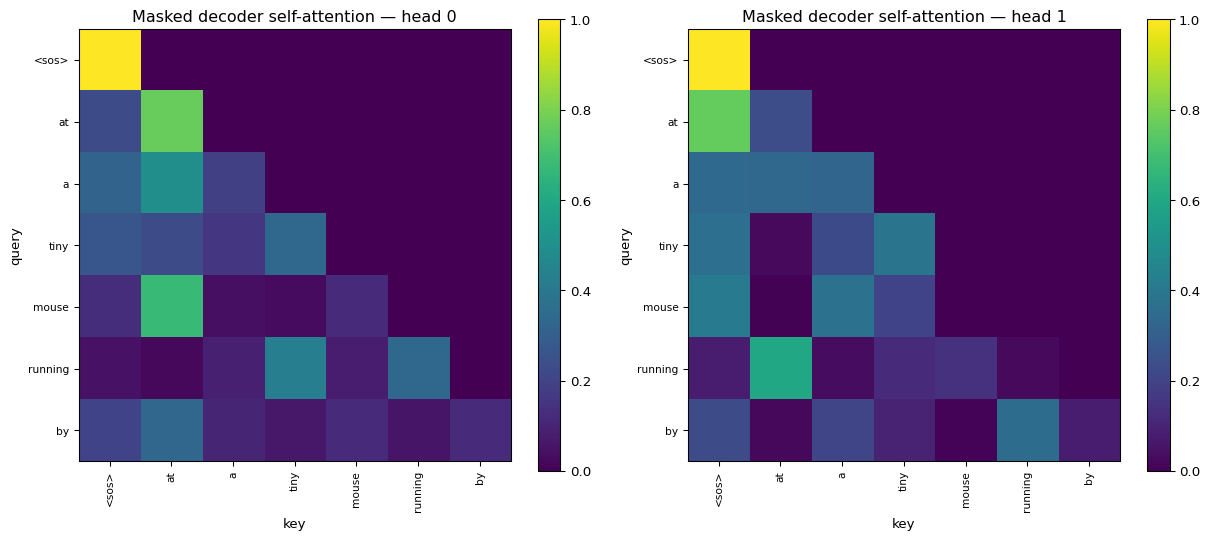

The black upper triangle is the mask: no token attends to its future.


In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
labels_dec = [id2word[i] for i in dec_input_ids]
for hh in range(N_HEADS):
    im = axes[hh].imshow(dec_w[hh], cmap="viridis", vmin=0)
    axes[hh].set(title=f"Masked decoder self-attention — head {hh}",
                 xlabel="key", ylabel="query")
    axes[hh].set_xticks(range(n_tgt), labels_dec, rotation=90, fontsize=8)
    axes[hh].set_yticks(range(n_tgt), labels_dec, fontsize=8)
    plt.colorbar(im, ax=axes[hh])
plt.tight_layout(); plt.show()
print("The black upper triangle is the mask: no token attends to its future.")

---
### Masked Self-Attention Matrices

The same seven steps as the encoder, with both operands and the full result
matrix printed at each one. Two things differ: every shape is 7 instead of 9,
and **step 4 applies the causal mask** between the scores and the softmax.

In [33]:
# ---- STEP 1 : project X_dec to Q (K and V are identical in form) ----
print("STEP 1 : project X_dec to Q (K and V are identical in form)")
print("=" * 78)
Qd_full = X_dec @ dec_self.Wq
show_matmul(X_dec, dec_self.Wq, Qd_full, "X_dec", "Wq", "Q_full",
            rows_A=labels_dec, note="K uses Wk, V uses Wv - same shapes, same arithmetic")

Kd_full = X_dec @ dec_self.Wk
Vd_full = X_dec @ dec_self.Wv
print(f"\nK_full = X_dec @ Wk -> {Kd_full.shape}")
print(f"V_full = X_dec @ Wv -> {Vd_full.shape}")

STEP 1 : project X_dec to Q (K and V are identical in form)
  X_dec (7, 8)   @   Wq (8, 8)   =   Q_full (7, 8)
  shape rule: (7 x 8) @ (8 x 8) -> (7 x 8)   inner dim 8 cancels
  K uses Wk, V uses Wv - same shapes, same arithmetic

X_dec =
        <sos> |   +1.382    +1.649    -0.167    +1.147    +1.207    +0.183    +0.369    +0.607
           at |   +2.015    +0.910    -0.007    +1.443    -1.561    -0.127    -1.193    +1.143
            a |   +0.129    +0.666    -1.151    +0.565    +0.054    +1.111    -0.177    +1.396
         tiny |   +0.449    -0.174    +1.156    +0.372    -0.137    +1.282    -0.246    +2.607
        mouse |   -0.320    +0.537    +1.339    -0.564    -2.514    +1.934    -1.363    +0.775
      running |   -1.805    -0.301    +0.001    +1.237    +2.399    +0.283    -0.412    +0.937
           by |   -0.123    +1.984    +0.740    -0.511    -0.352    +1.130    -0.449    +0.781

Wq =
     +0.420    -0.169    +0.197    -0.036    -0.369    +0.125    -0.538    -0.106
     +0.

In [34]:
# ---- STEP 2 : split the 8 columns into 2 heads of 4 ----
print("STEP 2 : split the 8 columns into 2 heads of 4")
print("=" * 78)
print(f"Q_full {Qd_full.shape}  ->  reshape({n_tgt}, {N_HEADS}, {D_K})  ->  transpose"
      f"  ->  ({N_HEADS}, {n_tgt}, {D_K})\n")
print(f"head 0 takes columns 0..3, head 1 takes columns 4..7\n")
print(f"Q head 0 {Qd[0].shape}:\n{np.round(Qd[0], 3)}")
print(f"\nQ head 1 {Qd[1].shape}:\n{np.round(Qd[1], 3)}")
print(f"\nmatches the column slices of Q_full: "
      f"{np.allclose(Qd[0], Qd_full[:, :D_K]) and np.allclose(Qd[1], Qd_full[:, D_K:])}")

STEP 2 : split the 8 columns into 2 heads of 4
Q_full (7, 8)  ->  reshape(7, 2, 4)  ->  transpose  ->  (2, 7, 4)

head 0 takes columns 0..3, head 1 takes columns 4..7

Q head 0 (7, 4):
[[ 1.335 -0.345 -0.441 -0.656]
 [ 2.61  -1.152  1.655  0.81 ]
 [ 0.609 -0.977 -0.584 -0.086]
 [ 2.543  0.313  0.482 -0.855]
 [ 1.285 -1.15   2.18   1.163]
 [-0.014  0.271 -2.035 -1.504]
 [ 0.726 -0.334  1.135  0.84 ]]

Q head 1 (7, 4):
[[ 0.681  0.293 -1.39   0.235]
 [-0.711 -0.363 -1.044 -0.108]
 [-0.503  0.945 -0.24  -0.129]
 [-2.001  2.057 -1.293 -2.201]
 [-1.923 -0.497 -0.963 -2.205]
 [ 1.646  1.387  0.663 -0.226]
 [-0.477 -0.576 -1.472 -1.461]]

matches the column slices of Q_full: True


In [35]:
# ---- STEP 3 : scores = Q0 @ K0^T, THEN divide by sqrt(d_k) ----
print("STEP 3 : scores = Q0 @ K0^T, THEN divide by sqrt(d_k)")
print("=" * 78)
dec_raw = Qd[0] @ Kd[0].T
show_matmul(Qd[0], Kd[0].T, dec_raw, "Q_head0", "K_head0^T", "raw_scores",
            rows_A=labels_dec, note="(7,4) @ (4,7) -> (7,7): 7 queries x 7 keys")

print(f"\nthen divide every entry by sqrt(d_k) = sqrt({D_K}) = {int(np.sqrt(D_K))}:\n")
scaled_dec = dec_raw / np.sqrt(D_K)
for r in range(n_tgt):
    print(f"   {labels_dec[r]:>10} | " + "  ".join(f"{v:+8.3f}" for v in scaled_dec[r]))
print(f"\n>>> still a full (7, 7) matrix - nothing is blocked yet.")

STEP 3 : scores = Q0 @ K0^T, THEN divide by sqrt(d_k)
  Q_head0 (7, 4)   @   K_head0^T (4, 7)   =   raw_scores (7, 7)
  shape rule: (7 x 4) @ (4 x 7) -> (7 x 7)   inner dim 4 cancels
  (7,4) @ (4,7) -> (7,7): 7 queries x 7 keys

Q_head0 =
        <sos> |   +1.335    -0.345    -0.441    -0.656
           at |   +2.610    -1.152    +1.655    +0.810
            a |   +0.609    -0.977    -0.584    -0.086
         tiny |   +2.543    +0.313    +0.482    -0.855
        mouse |   +1.285    -1.150    +2.180    +1.163
      running |   -0.014    +0.271    -2.035    -1.504
           by |   +0.726    -0.334    +1.135    +0.840

K_head0^T =
     +0.669    +0.249    -0.194    +0.637    -0.471    +0.225    +0.134
     +0.121    -1.721    +0.590    -0.852    -1.635    +0.651    +0.002
     +0.471    +1.726    +0.724    -0.595    +0.982    -1.013    +0.458
     -0.553    -1.444    -1.567    -2.151    -2.104    -0.996    -1.296

raw_scores =
        <sos> |   +1.007    +1.113    +0.246    +2.818    +0.

In [36]:
# ---- STEP 4 : apply the causal mask, BEFORE the softmax ----
print("STEP 4 : apply the causal mask, BEFORE the softmax")
print("=" * 78)
# This is the step that makes the decoder autoregressive.
print("Scaled scores + M.  Entries above the diagonal are set to -inf,")
print("so exp(-inf) = 0 and a future token can carry no weight.\n")

show_masked(dec_scores[0], causal_mask, "masked_scores", rows=labels_dec)

print(f"\n(-1e9 is used in code as a stand-in for -inf: exp(-1e9) underflows to")
print(f" exactly 0.0 in float64, while avoiding the 0 * inf = NaN edge case.)")

print(f"\n\nAfter the softmax those blocked entries become hard zeros:\n")
show_weights_masked(dec_w[0], causal_mask, "A = softmax(masked_scores)", rows=labels_dec)

print(f"\n   upper triangle is exactly 0 : {np.allclose(dec_w[0][causal_mask], 0.0)}")
print(f"   every row still sums to 1   : {np.round(dec_w[0].sum(axis=1), 6)}")
print(f"   non-zero entries per row    : {(dec_w[0] > 0).sum(axis=1)}  <- row t has t+1")

STEP 4 : apply the causal mask, BEFORE the softmax
Scaled scores + M.  Entries above the diagonal are set to -inf,
so exp(-inf) = 0 and a future token can carry no weight.

masked_scores =   (blocked entries shown as -inf)
        <sos> |   +0.503      -inf      -inf      -inf      -inf      -inf      -inf
           at |   +0.970    +2.161      -inf      -inf      -inf      -inf      -inf
            a |   +0.031    +0.475    -0.491      -inf      -inf      -inf      -inf
         tiny |   +1.220    +1.080    +0.690    +1.452      -inf      -inf      -inf
        mouse |   +0.552    +2.191    -0.586    -1.000    +0.484      -inf      -inf
      running |   -0.052    -0.905    +0.523    +2.104    +0.365    +1.867      -inf
           by |   +0.258    +0.751    -0.416    -0.868    -0.224    -1.020    -0.236

(-1e9 is used in code as a stand-in for -inf: exp(-1e9) underflows to
 exactly 0.0 in float64, while avoiding the 0 * inf = NaN edge case.)


After the softmax those blocked entries

In [37]:
# ---- STEP 5 : weights @ V, the masked weighted sum ----
print("STEP 5 : weights @ V, the masked weighted sum")
print("=" * 78)
dec_head0 = dec_w[0] @ Vd[0]
show_matmul(dec_w[0], Vd[0], dec_head0, "A (masked weights)", "V_head0", "head0_out",
            rows_A=labels_dec,
            note="(7,7)@(7,4) -> (7,4). Zero weights mean those V rows contribute nothing")

print(f"\n>>> row 0 has a single non-zero weight (1.0 on itself), so its output")
print(f">>> equals V row 0 exactly: {np.allclose(dec_head0[0], Vd[0][0])}")

STEP 5 : weights @ V, the masked weighted sum
  A (masked weights) (7, 7)   @   V_head0 (7, 4)   =   head0_out (7, 4)
  shape rule: (7 x 7) @ (7 x 4) -> (7 x 4)   inner dim 7 cancels
  (7,7)@(7,4) -> (7,4). Zero weights mean those V rows contribute nothing

A (masked weights) =
        <sos> |   +1.000    +0.000    +0.000    +0.000    +0.000    +0.000    +0.000
           at |   +0.233    +0.767    +0.000    +0.000    +0.000    +0.000    +0.000
            a |   +0.317    +0.495    +0.188    +0.000    +0.000    +0.000    +0.000
         tiny |   +0.269    +0.234    +0.158    +0.339    +0.000    +0.000    +0.000
        mouse |   +0.131    +0.676    +0.042    +0.028    +0.123    +0.000    +0.000
      running |   +0.050    +0.021    +0.088    +0.428    +0.075    +0.338    +0.000
           by |   +0.201    +0.329    +0.102    +0.065    +0.124    +0.056    +0.123

V_head0 =
     +0.597    -0.274    +1.040    -1.039
     +1.296    +0.654    +1.575    -2.918
     +0.529    -0.749    +1.454

In [38]:
# ---- STEPS 6 and 7 : concatenate the heads, then project with W_O ----
print("STEPS 6 and 7 : concatenate the heads, then project with W_O")
print("=" * 78)
dec_head1 = dec_w[1] @ Vd[1]
concat_d  = np.concatenate([dec_head0, dec_head1], axis=1)

print(f"dec_head0 {dec_head0.shape}   +   dec_head1 {dec_head1.shape}"
      f"   side by side   ->   concat {concat_d.shape}\n")
print(f"{'token':>10} | {'---- head 0 (dims 0-3) ----':^38} | {'---- head 1 (dims 4-7) ----':^38}")
print("-" * 92)
for r in range(concat_d.shape[0]):
    h0 = "  ".join(f"{v:+8.3f}" for v in dec_head0[r])
    h1 = "  ".join(f"{v:+8.3f}" for v in dec_head1[r])
    print(f"{labels_dec[r]:>10} | {h0} | {h1}")

print()
show_matmul(concat_d, dec_self.Wo, dec_attn_out, "concat", "W_O", "dec_attn_out",
            rows_A=labels_dec,
            note="W_O is what MIXES the two heads - this is the sub-layer's final output")

STEPS 6 and 7 : concatenate the heads, then project with W_O
dec_head0 (7, 4)   +   dec_head1 (7, 4)   side by side   ->   concat (7, 8)

     token |      ---- head 0 (dims 0-3) ----       |      ---- head 1 (dims 4-7) ----      
--------------------------------------------------------------------------------------------
     <sos> |   +0.597    -0.274    +1.040    -1.039 |   -1.693    +0.565    +0.092    -1.168
        at |   +1.133    +0.438    +1.451    -2.480 |   -1.629    +0.983    -0.221    -0.983
         a |   +0.930    +0.096    +1.383    -1.666 |   -1.266    +0.861    -0.252    -0.567
      tiny |   +0.904    -0.083    +1.639    -0.690 |   -1.002    +0.785    +0.393    -1.023
     mouse |   +1.212    +0.609    +1.375    -2.245 |   -1.065    +0.435    +0.340    -0.832
   running |   +0.459    -0.328    +1.165    +0.832 |   -1.040    +1.642    -0.355    -0.613
        by |   +1.023    +0.352    +1.044    -1.221 |   -0.754    +0.231    +0.862    -0.728

  concat (7, 8)   @   W_

### Decoder Add & Norm (1)

$$Y_1 = \mathrm{LayerNorm}\big(X_{dec} + \mathrm{MaskedMultiHead}(X_{dec})\big)$$

In [39]:
g1_d, b1_d = ln_params()
dec_res1  = X_dec + dec_attn_out
dec_norm1 = layer_norm(dec_res1, g1_d, b1_d)

show_elementwise(X_dec, dec_attn_out, dec_res1,
                 "X_dec", "attn_out", "residual", "+", rows=labels_dec)

print(f"\n\nthen LayerNorm, row by row -> Y1 (shape {dec_norm1.shape}):\n")
for r in range(n_tgt):
    print(f"   {labels_dec[r]:>10} | " + "  ".join(f"{v:+8.3f}" for v in dec_norm1[r]))
print(f"\nmean={dec_norm1.mean():+.4f}, per-row std={np.round(dec_norm1.std(axis=1), 3)}")

  residual = X_dec + attn_out      all three are (7, 8) — element-wise, no mixing

     <sos> | 
            X_dec:   +1.382    +1.649    -0.167    +1.147    +1.207    +0.183    +0.369    +0.607
         attn_out:   -0.474    -0.135    +1.012    -0.026    -1.654    -0.811    +0.254    -1.065
         residual:   +0.908    +1.514    +0.845    +1.120    -0.447    -0.628    +0.623    -0.458

        at | 
            X_dec:   +2.015    +0.910    -0.007    +1.443    -1.561    -0.127    -1.193    +1.143
         attn_out:   -0.739    -0.320    +1.676    -1.196    -1.742    -0.106    +0.533    -1.575
         residual:   +1.276    +0.590    +1.669    +0.247    -3.303    -0.232    -0.660    -0.432

         a | 
            X_dec:   +0.129    +0.666    -1.151    +0.565    +0.054    +1.111    -0.177    +1.396
         attn_out:   -0.739    -0.063    +1.466    -0.658    -1.290    -0.138    +0.563    -1.420
         residual:   -0.609    +0.603    +0.315    -0.093    -1.236    +0.973    +0.386  

---
# 13. Decoder: Cross-Attention

**This is the one place where the encoder and the decoder communicate**, and the shapes stop being square:

$$Q = Y_1 W^Q \quad \text{from the \textbf{decoder}} \qquad
K = H W^K, \;\; V = H W^V \quad \text{from the \textbf{encoder output } } H$$

| | comes from | shape |
|---|---|---|
| $Q$ | **decoder**, $Y_1$ | $(7, 8) \rightarrow$ per head $(2, 7, 4)$ |
| $K$, $V$ | **encoder** output $H$ | $(9, 8) \rightarrow$ per head $(2, 9, 4)$ |
| scores $QK^\top$ | | $(2, \mathbf{7}, \mathbf{9})$ |
| output | | $(7, 8)$ |

Read the $7 \times 9$ score matrix as: *for each of the 7 decoder positions, how much attention is paid to each of the 9 prefix words.* Each **row** sums to 1 across the 9 prefix tokens. This is the conditioning on $x$ in $P(y_t \mid y_{<t}, x)$ — without this sub-layer the decoder would be a plain language model that had never seen the prefix.

Two things to be careful about:

1. **No causal mask here.** The decoder is allowed to look at the *entire* prefix at every step. The prefix is given, not generated, so there is no future to hide. The causal constraint lives only in the decoder's *self*-attention.
2. **$K$ and $V$ are computed once** and reused at every generation step — only $Q$ changes, because only the decoder side grows. This is why encoder–decoder models cache the encoder output.

In [40]:
cross = MHA(name="cross-attention")
cross_out, cross_w, cross_scores, (Qc, Kc, Vc, _) = cross(
    dec_norm1, encoder_output, mask=None, verbose=True)

print(f"\nQ comes from the DECODER : {dec_norm1.shape}  -> per head {Qc.shape}")
print(f"K,V come from the ENCODER: {encoder_output.shape}  -> per head {Kc.shape}")
print(f"Score matrix is rectangular: {cross_scores.shape}  (heads, n_tgt, n_src)\n")
print(f"--- Head 0: cross-attention weights ({n_tgt} decoder x {n_src} prefix) ---")
print(np.round(cross_w[0], 4))
print(f"\nEach row sums to 1 over the {n_src} prefix tokens: "
      f"{np.allclose(cross_w.sum(axis=-1), 1.0)}")

[cross-attention] x_q (7, 8) , x_kv (9, 8)
  Q,K,V per head: (2, 7, 4), (2, 9, 4), (2, 9, 4)
  scores/weights: (2, 7, 9)   concat: (7, 8)   out: (7, 8)

Q comes from the DECODER : (7, 8)  -> per head (2, 7, 4)
K,V come from the ENCODER: (9, 8)  -> per head (2, 9, 4)
Score matrix is rectangular: (2, 7, 9)  (heads, n_tgt, n_src)

--- Head 0: cross-attention weights (7 decoder x 9 prefix) ---
[[0.144 0.088 0.091 0.091 0.068 0.018 0.002 0.448 0.05 ]
 [0.005 0.004 0.429 0.338 0.004 0.    0.002 0.005 0.212]
 [0.034 0.039 0.222 0.204 0.044 0.029 0.184 0.019 0.225]
 [0.004 0.006 0.387 0.279 0.007 0.001 0.041 0.004 0.271]
 [0.004 0.004 0.362 0.289 0.005 0.001 0.036 0.001 0.298]
 [0.069 0.074 0.001 0.001 0.07  0.43  0.009 0.345 0.001]
 [0.035 0.029 0.269 0.255 0.037 0.015 0.077 0.011 0.272]]

Each row sums to 1 over the 9 prefix tokens: True


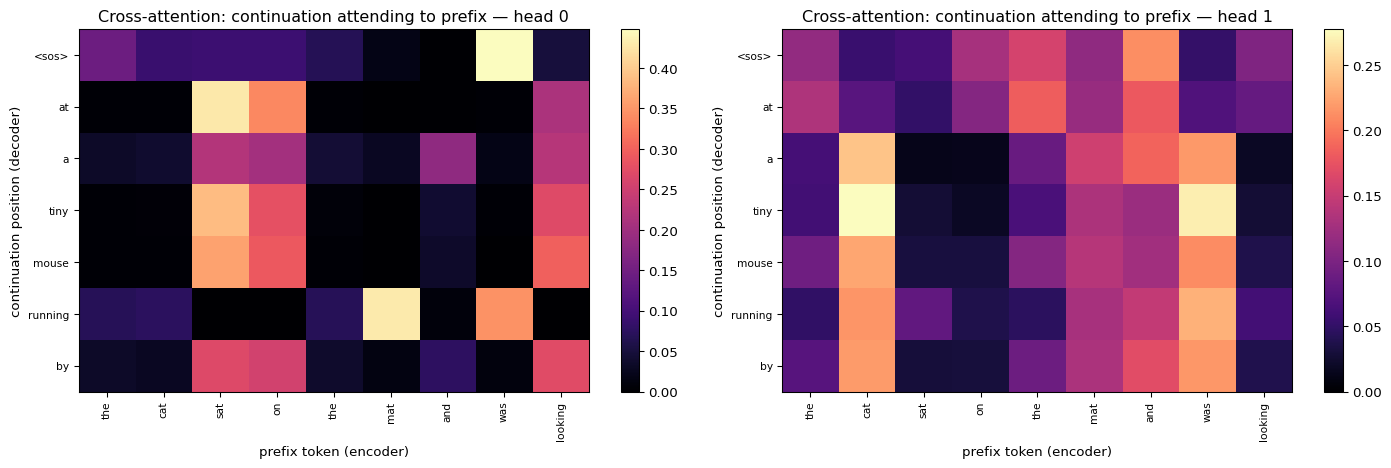

Decoder position 3 ('tiny') attends most to prefix tokens:
   'sat' (pos 2): 0.3868
   'on' (pos 3): 0.2788
   'looking' (pos 8): 0.2714

(With untrained weights this is arbitrary — a trained model would concentrate on the prefix words that actually constrain the next token.)


In [41]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for hh in range(N_HEADS):
    im = axes[hh].imshow(cross_w[hh], cmap="magma", aspect="auto", vmin=0)
    axes[hh].set(title=f"Cross-attention: continuation attending to prefix — head {hh}",
                 xlabel="prefix token (encoder)", ylabel="continuation position (decoder)")
    axes[hh].set_xticks(range(n_src), src_tokens, rotation=90, fontsize=8)
    axes[hh].set_yticks(range(n_tgt), labels_dec, fontsize=8)
    plt.colorbar(im, ax=axes[hh])
plt.tight_layout(); plt.show()

t = 3
top = np.argsort(-cross_w[0, t])[:3]
print(f"Decoder position {t} ('{labels_dec[t]}') attends most to prefix tokens:")
for k in top:
    print(f"   '{src_tokens[k]}' (pos {k}): {cross_w[0, t, k]:.4f}")
print("\n(With untrained weights this is arbitrary — a trained model would "
      "concentrate on the prefix words that actually constrain the next token.)")

---
### Cross-Attention Matrices

Here the two stacks meet, and the operands come from **different places**. This is the clearest place to see why shapes work out:

| operation | shapes | result |
|---|---|---|
| $Q$ from decoder $Y_1$ | $(7,8) @ (8,8)$ | $(7,8) \to$ head $(7,4)$ |
| $K$ from encoder $H$ | $(9,8) @ (8,8)$ | $(9,8) \to$ head $(9,4)$ |
| $Q_0 K_0^\top$ | $(7,4) @ (4,9)$ | $(\mathbf{7},\mathbf{9})$ |
| $A V_0$ | $(7,9) @ (9,4)$ | $(\mathbf{7},4)$ |

The output has **7 rows** (one per decoder position) and **4 columns per head** — the 9 prefix positions appear only as the summed-over dimension. The decoder gets back exactly its own shape, having absorbed information from a sequence of a different length.

In [42]:
Qc_full = dec_norm1 @ cross.Wq          # from the DECODER
Kc_full = encoder_output @ cross.Wk     # from the ENCODER
print(f"Q source = dec_norm1        {dec_norm1.shape}   (decoder)")
print(f"K,V source = encoder_output {encoder_output.shape}   (encoder)\n")

cross_raw = Qc[0] @ Kc[0].T
show_matmul(Qc[0], Kc[0].T, cross_raw, "Q_dec_head0", "K_enc_head0^T", "raw_scores",
            rows_A=labels_dec,
            note="rows indexed by DECODER positions, columns by PREFIX positions")

print(f"\ncolumn labels are the prefix tokens: {src_tokens}")

Q source = dec_norm1        (7, 8)   (decoder)
K,V source = encoder_output (9, 8)   (encoder)

  Q_dec_head0 (7, 4)   @   K_enc_head0^T (4, 9)   =   raw_scores (7, 9)
  shape rule: (7 x 4) @ (4 x 9) -> (7 x 9)   inner dim 4 cancels
  rows indexed by DECODER positions, columns by PREFIX positions

Q_dec_head0 =
        <sos> |   -1.283    +0.863    -0.584    +2.871
           at |   +0.054    -0.599    +1.694    +2.945
            a |   +0.547    -0.652    +0.976    -0.296
         tiny |   +1.658    -0.365    +1.646    +1.304
        mouse |   +1.061    -1.398    +1.859    +0.975
      running |   -0.135    +1.784    -2.773    -0.212
           by |   +0.329    -1.214    +0.509    +0.816

K_enc_head0^T =
     -1.745    -1.226    +0.050    -0.148    -0.856    -0.898    +1.177    -1.513    +0.188
     -0.360    -0.008    -1.309    -1.395    -0.341    -0.161    -1.431    +1.839    -1.672
     -0.470    -0.308    +2.101    +1.958    -0.500    -1.599    +0.232    -0.248    +1.714
     -0.05

In [43]:
cross_head0 = cross_w[0] @ Vc[0]
show_matmul(cross_w[0], Vc[0], cross_head0, "A (7x9)", "V_enc_head0 (9x4)", "head0_out (7x4)",
            rows_A=labels_dec,
            note="the 9 PREFIX positions cancel — output keeps the decoder's 7 rows")

print(f"\n>>> (7,9) @ (9,4) = (7,4).  Encoder length 9 vanishes into the sum.")
print(f">>> This is how a decoder of length 7 reads a source of length 9.")

  A (7x9) (7, 9)   @   V_enc_head0 (9x4) (9, 4)   =   head0_out (7x4) (7, 4)
  shape rule: (7 x 9) @ (9 x 4) -> (7 x 4)   inner dim 9 cancels
  the 9 PREFIX positions cancel — output keeps the decoder's 7 rows

A (7x9) =
        <sos> |   +0.144    +0.088    +0.091    +0.091    +0.068    +0.018    +0.002    +0.448    +0.050
           at |   +0.005    +0.004    +0.429    +0.338    +0.004    +0.000    +0.002    +0.005    +0.212
            a |   +0.034    +0.039    +0.222    +0.204    +0.044    +0.029    +0.184    +0.019    +0.225
         tiny |   +0.004    +0.006    +0.387    +0.279    +0.007    +0.001    +0.041    +0.004    +0.271
        mouse |   +0.004    +0.004    +0.362    +0.289    +0.005    +0.001    +0.036    +0.001    +0.298
      running |   +0.069    +0.074    +0.001    +0.001    +0.070    +0.430    +0.009    +0.345    +0.001
           by |   +0.035    +0.029    +0.269    +0.255    +0.037    +0.015    +0.077    +0.011    +0.272

V_enc_head0 (9x4) =
     +0.972    -0.975  

### Decoder Add & Norm (2)

$$Y_2 = \mathrm{LayerNorm}\big(Y_1 + \mathrm{CrossAttention}(Y_1, H)\big)$$

Note the residual adds $Y_1$ — the *decoder* stream — not the encoder output. The encoder information enters only through the attention output. This keeps the decoder's own representation as the backbone.

In [44]:
g2_d, b2_d = ln_params()
dec_norm2 = layer_norm(dec_norm1 + cross_out, g2_d, b2_d)
print(f"Decoder Add&Norm 2 (shape {dec_norm2.shape}):\n{np.round(dec_norm2, 3)}")

Decoder Add&Norm 2 (shape (7, 8)):
[[ 0.764  1.392  0.269  0.846 -1.436 -0.636  0.269 -1.467]
 [ 1.128  0.09   1.533  0.505 -1.823 -0.364 -0.328 -0.741]
 [-1.147  0.963  0.417 -0.026 -1.832  1.408  0.438 -0.221]
 [-0.447 -0.56   2.124  0.323 -1.345 -0.258 -0.62   0.783]
 [-0.493 -0.006  2.077 -0.293 -1.413  0.988 -0.514 -0.345]
 [-1.54   1.181 -0.292  1.414  0.74  -0.902  0.25  -0.851]
 [-0.974  1.342  1.715 -0.487 -0.987  0.564 -0.8   -0.373]]


---
# 14. Decoder: Feed-Forward Network

Identical in form to the encoder FFN, with its own weights:

$$\mathrm{FFN}(x) = \max(0, xW_1 + b_1)W_2 + b_2, \qquad
\text{decoder\_output} = \mathrm{LayerNorm}\big(Y_2 + \mathrm{FFN}(Y_2)\big)$$

In [45]:
W1_d, b1f_d = xavier(D_MODEL, D_FF), np.zeros(D_FF)
W2_d, b2f_d = xavier(D_FF, D_MODEL), np.zeros(D_MODEL)
g3_d, b3_d  = ln_params()

lin1_d = dec_norm2 @ W1_d + b1f_d
relu_d = np.maximum(0, lin1_d)
ffn_d  = relu_d @ W2_d + b2f_d
decoder_output = layer_norm(dec_norm2 + ffn_d, g3_d, b3_d)

print(f"{dec_norm2.shape} -> W1 -> {lin1_d.shape} -> ReLU -> W2 -> {ffn_d.shape}")
print(f"({(relu_d == 0).mean()*100:.1f}% of hidden units zeroed by ReLU)\n")
print(f"DECODER OUTPUT (shape {decoder_output.shape}):\n{np.round(decoder_output, 3)}")
print(f"\nmean = {decoder_output.mean():+.4f}, std = {decoder_output.std():.4f}")
print("Magnitudes stay O(1) through the whole network — contrast with ~80 000 before.")

(7, 8) -> W1 -> (7, 32) -> ReLU -> W2 -> (7, 8)
(49.6% of hidden units zeroed by ReLU)

DECODER OUTPUT (shape (7, 8)):
[[ 0.427  1.034  0.123  1.27  -0.264 -0.185 -0.171 -2.233]
 [ 0.851 -0.119  1.272  1.394 -0.955 -0.262 -0.678 -1.503]
 [-1.206  0.158  0.225  0.322 -0.799  2.268 -0.245 -0.722]
 [-0.107 -1.762  1.586  0.781 -0.874  0.396 -0.657  0.636]
 [-0.541 -0.844  1.685  0.095 -0.302  1.61  -0.936 -0.766]
 [-1.514  0.464 -0.833  1.901  0.461  0.283  0.168 -0.93 ]
 [-0.707  0.527  1.426 -0.643  0.119  1.46  -1.444 -0.738]]

mean = +0.0000, std = 1.0000
Magnitudes stay O(1) through the whole network — contrast with ~80 000 before.


---
# 15. Output Projection

The decoder produced 7 vectors of dimension 8. To predict tokens they must be projected onto the vocabulary:

$$\text{logits} = \text{decoder\_output} \cdot W_{out} + b_{out}, \qquad W_{out} \in \mathbb{R}^{d_{model} \times V} = \mathbb{R}^{8 \times 500}$$

$$(7 \times 8) \cdot (8 \times 500) = (7 \times 500)$$

Row $t$, column $v$ of the result is the **unnormalized score** ("logit") that token $v$ is the correct continuation at position $t$.

**Weight tying.** The paper shares this matrix with the embedding table: $W_{out} = E^\top$. Two reasons —

* *Parameter economy*: $V \times d_{model} = 4000$ parameters saved here, hundreds of millions in a real model.
* *Interpretation*: the logit becomes a **dot product between the decoder's output vector and the embedding of each candidate token**,
  $\text{logit}_{t,v} = \langle \text{decoder\_output}_t,\; E_v \rangle$.
  So the model is literally asking "which token's embedding does my prediction vector point at most?" — a nearest-neighbour search in embedding space, measured by inner product.

This is why keeping the random IDs in [50, 500) is fine: the projection covers all 500 vocabulary slots, and the handful that correspond to real words simply have meaningful embeddings while the rest are unused noise.

In [46]:
W_out = E.T                      # weight tying: (8, 500)
b_out = np.zeros(VOCAB_SIZE)

logits = decoder_output @ W_out + b_out       # (7, 500)

print(f"decoder_output {decoder_output.shape} @ W_out {W_out.shape} = logits {logits.shape}\n")
print(f"Logits for the last position (t = {n_tgt-1}), first 12 vocabulary entries:")
print(np.round(logits[-1, :12], 4))
print(f"\nrange over the whole matrix: [{logits.min():.3f}, {logits.max():.3f}]")

# Hand check of one logit
t, v = n_tgt - 1, int(labels[-1])       # last position, the <eos> token
manual = float(np.dot(decoder_output[t], E[v]))
print(f"\nHand check  logit[t={t}, v={v} ('{id2word[v]}')]"
      f" = <decoder_output[{t}], E[{v}]>")
print(f"  = " + " + ".join(f"({a:.3f})({b:.3f})" for a, b in zip(decoder_output[t], E[v])))
print(f"  = {manual:.6f}")
print(f"  from logits matrix: {logits[t, v]:.6f}   match: {np.isclose(manual, logits[t, v])}")

decoder_output (7, 8) @ W_out (8, 500) = logits (7, 500)

Logits for the last position (t = 6), first 12 vocabulary entries:
[-0.721 -0.798 -0.249 -0.334  0.354  3.275 -0.734  0.531 -0.554  0.007  0.205 -0.104]

range over the whole matrix: [-4.153, 3.611]

Hand check  logit[t=6, v=2 ('<eos>')] = <decoder_output[6], E[2]>
  = (-0.707)(0.010) + (0.527)(0.452) + (1.426)(0.068) + (-0.643)(0.016) + (0.119)(-0.481) + (1.460)(0.264) + (-1.444)(0.228) + (-0.738)(0.765)
  = -0.249453
  from logits matrix: -0.249453   match: True


---
### Output Projection Matrix

In [47]:
show_matmul(decoder_output, W_out, logits,
            "decoder_output (7,8)", "W_out = E^T (8,500)", "logits (7,500)",
            rows_A=labels_dec, max_cols=10,
            note="8 collapses, 500 opens up: one score per vocabulary entry per position")

print(f"\n>>> the only step where the width EXPANDS: 8 -> 500.")
print(f">>> {decoder_output.shape[0]} * {D_MODEL} * {VOCAB_SIZE} = "
      f"{decoder_output.shape[0]*D_MODEL*VOCAB_SIZE:,} multiply-adds, "
      f"more than the rest of the decoder combined.")
print(f"\n>>> then softmax turns each of the {n_tgt} rows into a distribution over "
      f"{VOCAB_SIZE} tokens.")

  decoder_output (7,8) (7, 8)   @   W_out = E^T (8,500) (8, 500)   =   logits (7,500) (7, 500)
  shape rule: (7 x 8) @ (8 x 500) -> (7 x 500)   inner dim 8 cancels
  8 collapses, 500 opens up: one score per vocabulary entry per position

decoder_output (7,8) =
        <sos> |   +0.427    +1.034    +0.123    +1.270    -0.264    -0.185    -0.171    -2.233
           at |   +0.851    -0.119    +1.272    +1.394    -0.955    -0.262    -0.678    -1.503
            a |   -1.206    +0.158    +0.225    +0.322    -0.799    +2.268    -0.245    -0.722
         tiny |   -0.107    -1.762    +1.586    +0.781    -0.874    +0.396    -0.657    +0.636
        mouse |   -0.541    -0.844    +1.685    +0.095    -0.302    +1.610    -0.936    -0.766
      running |   -1.514    +0.464    -0.833    +1.901    +0.461    +0.283    +0.168    -0.930
           by |   -0.707    +0.527    +1.426    -0.643    +0.119    +1.460    -1.444    -0.738

W_out = E^T (8,500) =   [showing first 10 of 500 columns]
     +0.206    

---
# 16. Softmax: Next-Token Distribution

$$P(y_t = v \mid y_{<t},\, x) = \frac{\exp(\text{logit}_{t,v})}{\sum_{v'=1}^{V} \exp(\text{logit}_{t,v'})}$$

Each of the 7 rows becomes a probability distribution over all 500 tokens, summing to 1. This is the autoregressive factorization made concrete: **row $t$ is one factor of the product** $\prod_t P(y_t \mid y_{<t}, x)$.

**The prediction of the next token is the last row.** Position $t = 6$ has seen the prefix (through cross-attention) plus `<sos> at a tiny mouse running by` — the complete continuation so far — so its distribution answers *"what comes after `by`?"* (the correct answer being `<eos>`, since the sentence ends there).

Rows $0 \dots 5$ are predictions too — they are what the loss is computed on during training — but only the last one is used when generating.

In [48]:
probs = softmax(logits, axis=-1)              # (11, 500)

print(f"probs shape {probs.shape}, every row sums to 1: "
      f"{np.allclose(probs.sum(axis=1), 1.0)}\n")

last = probs[-1]
top5 = np.argsort(-last)[:5]
print(f"Prefix  (encoder): '{' '.join(src_tokens)}'")
print(f"Context (decoder): '{' '.join(labels_dec)}'")
print(f"Question: what token comes next?\n")
print(f"{'rank':>4}  {'id':>4}  {'token':<12} {'logit':>9}  {'probability':>12}")
print("-" * 50)
for r, v in enumerate(top5, 1):
    w = id2word.get(int(v), f"<unused_{v}>")
    print(f"{r:>4}  {v:>4}  {w:<12} {logits[-1, v]:>9.4f}  {last[v]:>12.6f}")

pred_id = int(np.argmax(last))
print(f"\nPREDICTED NEXT TOKEN: id {pred_id} -> "
      f"'{id2word.get(pred_id, f'<unused_{pred_id}>')}'")
print(f"True next token     : id {labels[-1]} -> '{id2word[int(labels[-1])]}'")
print(f"\nProbability assigned to the true token: {last[labels[-1]]:.6f}")
print(f"Uniform baseline (1/V)                : {1/VOCAB_SIZE:.6f}")
print("\nWith random weights the prediction is essentially chance — as expected. "
      "The arithmetic is correct; the model is simply untrained.")

probs shape (7, 500), every row sums to 1: True

Prefix  (encoder): 'the cat sat on the mat and was looking'
Context (decoder): '<sos> at a tiny mouse running by'
Question: what token comes next?

rank    id  token            logit   probability
--------------------------------------------------
   1     5  <unused_5>      3.2750      0.033622
   2   342  <unused_342>    2.9872      0.025214
   3   190  <unused_190>    2.7904      0.020711
   4   487  <unused_487>    2.5049      0.015566
   5   208  <unused_208>    2.4846      0.015253

PREDICTED NEXT TOKEN: id 5 -> '<unused_5>'
True next token     : id 2 -> '<eos>'

Probability assigned to the true token: 0.000991
Uniform baseline (1/V)                : 0.002000

With random weights the prediction is essentially chance — as expected. The arithmetic is correct; the model is simply untrained.


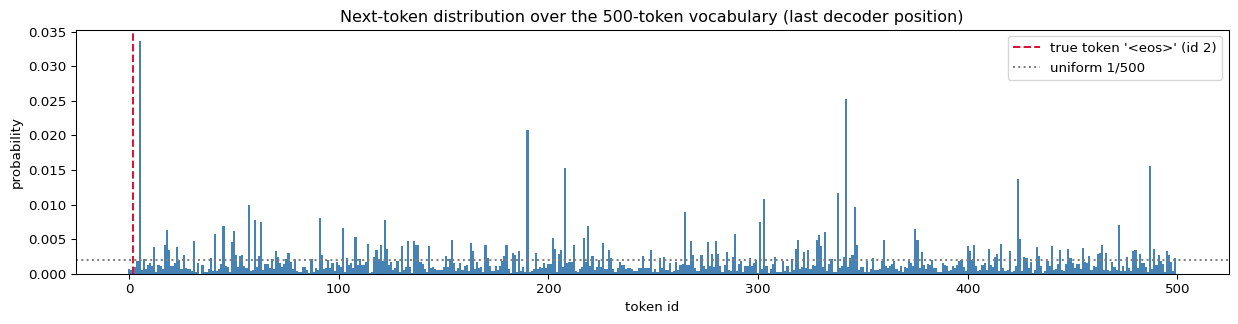

max probability = 0.03362 at id 5
entropy = 5.6914 nats (maximum possible = log(500) = 6.2146)


In [49]:
plt.figure(figsize=(13, 3.5))
plt.bar(np.arange(VOCAB_SIZE), last, width=1.0, color="steelblue")
plt.axvline(labels[-1], color="crimson", ls="--", lw=1.5,
            label=f"true token '{id2word[int(labels[-1])]}' (id {labels[-1]})")
plt.axhline(1/VOCAB_SIZE, color="gray", ls=":", label="uniform 1/500")
plt.title("Next-token distribution over the 500-token vocabulary (last decoder position)")
plt.xlabel("token id"); plt.ylabel("probability"); plt.legend(); plt.tight_layout(); plt.show()

print(f"max probability = {last.max():.5f} at id {last.argmax()}")
print(f"entropy = {-(last * np.log(last + 1e-12)).sum():.4f} nats "
      f"(maximum possible = log(500) = {np.log(500):.4f})")

---
# 17. Decoding Strategies

Turning the distribution into a token is a separate decision, not part of the model.

**Greedy** — take the mode:
$$\hat{v} = \arg\max_v P(v)$$
Deterministic, but tends to produce repetitive text.

**Temperature $T$** — rescale the logits before the softmax:
$$P_T(v) = \frac{\exp(\text{logit}_v / T)}{\sum_{v'} \exp(\text{logit}_{v'} / T)}$$
* $T \to 0$: distribution collapses onto the argmax (greedy).
* $T = 1$: unchanged.
* $T > 1$: flatter, more random.

Temperature is a *monotone* transformation of the logits, so it never changes the ranking — only how sharply the mass concentrates. Entropy is the quantity to watch.

**Top-$k$** — keep the $k$ highest logits, set the rest to $-\infty$, renormalize, sample. This truncates the long tail of 495 implausible tokens that collectively can still hold non-trivial probability mass.

In [50]:
def apply_temperature(logits_row, T):
    return softmax(logits_row / T)

print(f"{'T':>6}  {'entropy (nats)':>15}  {'max prob':>10}  {'argmax id':>10}")
print("-" * 48)
for T in [0.1, 0.5, 1.0, 2.0, 5.0]:
    p = apply_temperature(logits[-1], T)
    H = -(p * np.log(p + 1e-12)).sum()
    print(f"{T:>6.1f}  {H:>15.4f}  {p.max():>10.5f}  {p.argmax():>10}")

print("\nThe argmax is identical for every T — temperature reshapes, never reorders.\n")

k = 5
topk_idx = np.argsort(-logits[-1])[:k]
masked = np.full(VOCAB_SIZE, -1e9)
masked[topk_idx] = logits[-1, topk_idx]
p_topk = softmax(masked)
print(f"Top-{k} renormalized distribution:")
for v in topk_idx:
    print(f"   id {v:>3} '{id2word.get(int(v), '<unused>')}' : "
          f"{last[v]:.6f}  ->  {p_topk[v]:.4f}")
print(f"   (the other {VOCAB_SIZE-k} tokens: probability exactly 0)")

rng = np.random.default_rng(7)
draws = rng.choice(VOCAB_SIZE, size=8, p=p_topk)
print(f"\n8 samples from the top-{k} distribution: {draws}")

     T   entropy (nats)    max prob   argmax id
------------------------------------------------
   0.1           0.2585     0.93886           5
   0.5           4.0472     0.19117           5
   1.0           5.6914     0.03362           5
   2.0           6.0906     0.00931           5
   5.0           6.1952     0.00381           5

The argmax is identical for every T — temperature reshapes, never reorders.

Top-5 renormalized distribution:
   id   5 '<unused>' : 0.033622  ->  0.3046
   id 342 '<unused>' : 0.025214  ->  0.2285
   id 190 '<unused>' : 0.020711  ->  0.1877
   id 487 '<unused>' : 0.015566  ->  0.1410
   id 208 '<unused>' : 0.015253  ->  0.1382
   (the other 495 tokens: probability exactly 0)

8 samples from the top-5 distribution: [208 487 342   5   5 487   5 342]


---
# 18. Cross-Entropy Loss

Prediction and training are two sides of the same forward pass. The loss at position $t$ is the negative log-probability the model assigned to the correct token:

$$\mathcal{L}_t = -\log P_t(\text{label}_t), \qquad
\mathcal{L} = \frac{1}{n_{tgt}} \sum_{t=0}^{n_{tgt}-1} \mathcal{L}_t$$

Two reference values are useful for sanity-checking any implementation:

* An **untrained** model should score $\mathcal{L} \approx \log V = \log 500 \approx 6.21$, i.e. chance level. In practice it lands slightly *above* $\log V$: the random distribution is not uniform, so it is confidently wrong on some positions, and $-\log p$ punishes that asymmetrically. Anything in the range $6$–$8$ here is normal; a value near $0$ would mean the labels are leaking into the input.
* **Perplexity** $= e^{\mathcal{L}}$ is the effective number of tokens the model is choosing between. At initialization it should be $\approx V$.

If a fresh implementation starts far from $\log V$, something is wrong (usually a mask leak or a label misalignment). All 7 positions contribute — this is why teacher forcing is efficient: one forward pass yields 7 training signals, one per factor of the autoregressive product.

In [51]:
p_true = probs[np.arange(n_tgt), labels]
loss_t = -np.log(p_true + 1e-12)
loss   = loss_t.mean()

print(f"{'t':>3}  {'input':<12} {'label':<12} {'P(label)':>10}  {'-log P':>8}")
print("-" * 52)
for t in range(n_tgt):
    print(f"{t:>3}  {id2word[dec_input_ids[t]]:<12} {id2word[int(labels[t])]:<12} "
          f"{p_true[t]:>10.6f}  {loss_t[t]:>8.4f}")

print("-" * 52)
print(f"Mean cross-entropy loss : {loss:.4f}")
print(f"log(V) = log({VOCAB_SIZE})       : {np.log(VOCAB_SIZE):.4f}   <- untrained reference")
print(f"Perplexity  exp(loss)   : {np.exp(loss):.1f}  (vs V = {VOCAB_SIZE})")
print(f"\nThe loss is at chance level (slightly above log V, as expected for a random "
      f"\nnon-uniform distribution). Training would drive it toward 0; backpropagation "
      f"\nis out of scope for this notebook.")

  t  input        label          P(label)    -log P
----------------------------------------------------
  0  <sos>        at             0.002379    6.0412
  1  at           a              0.000329    8.0187
  2  a            tiny           0.001004    6.9041
  3  tiny         mouse          0.001992    6.2188
  4  mouse        running        0.000786    7.1490
  5  running      by             0.000530    7.5420
  6  by           <eos>          0.000991    6.9170
----------------------------------------------------
Mean cross-entropy loss : 6.9701
log(V) = log(500)       : 6.2146   <- untrained reference
Perplexity  exp(loss)   : 1064.3  (vs V = 500)

The loss is at chance level (slightly above log V, as expected for a random 
non-uniform distribution). Training would drive it toward 0; backpropagation 
is out of scope for this notebook.


---
# 19. Autoregressive Generation

Everything above computed all 7 positions at once, using the *true* continuation as decoder input (teacher forcing). At **inference time** the true continuation does not exist, so the decoder must be run repeatedly, feeding back its own predictions. This is the loop that the word "autoregressive" actually names:

```
H = Encoder(prefix)                 # computed ONCE
y = [<sos>]
repeat:
    logits = Decoder(y, H)          # full re-run over the prefix of y
    next   = argmax(softmax(logits[-1]))
    y.append(next)
until next == <eos> or len(y) > max_len
```

Three points that are easy to miss:

1. **The encoder runs once.** $H$, and therefore cross-attention's $K$ and $V$, never change. Only the decoder is re-executed. Every generated token is conditioned on the same 9-token prefix.
2. **Step $t$ costs a full decoder pass over $t{+}1$ positions.** Positions $0 \dots t-1$ recompute identical values, because the causal mask guarantees they cannot depend on the newly appended token. Real implementations exploit this with a **KV cache**, storing $K$ and $V$ per position; the naive loop below recomputes them so the mechanism stays visible.
3. **The causal mask is still required** even though nothing to the right exists yet — it is what makes point 2 true, and it keeps training and inference behaviour identical.

The two functions below wrap the exact same weights and operations used above.

In [52]:
def encoder_forward(ids):
    x = E[ids] * scale + positional_encoding(len(ids), D_MODEL)
    a, _, _, _ = enc_self(x, x, mask=None)
    x = layer_norm(x + a, g1_e, b1_e)
    f = np.maximum(0, x @ W1_e + b1f_e) @ W2_e + b2f_e
    return layer_norm(x + f, g2_e, b2_e)

def decoder_forward(ids, H):
    n = len(ids)
    x = E[ids] * scale + positional_encoding(n, D_MODEL)
    m = np.triu(np.ones((n, n), dtype=bool), k=1)
    a, _, _, _ = dec_self(x, x, mask=m)
    x = layer_norm(x + a, g1_d, b1_d)
    c, cw, _, _ = cross(x, H, mask=None)
    x = layer_norm(x + c, g2_d, b2_d)
    f = np.maximum(0, x @ W1_d + b1f_d) @ W2_d + b2f_d
    x = layer_norm(x + f, g3_d, b3_d)
    return x @ W_out + b_out, cw

# Verify the functions reproduce the step-by-step computation exactly
H_check = encoder_forward(src_ids)
L_check, _ = decoder_forward(dec_input_ids, H_check)
print(f"encoder_forward matches encoder_output : {np.allclose(H_check, encoder_output)}")
print(f"decoder_forward matches logits         : {np.allclose(L_check, logits)}")

encoder_forward matches encoder_output : True
decoder_forward matches logits         : True


In [53]:
def generate(src_ids, max_len=12, temperature=1.0, greedy=True, seed=0):
    rng = np.random.default_rng(seed)
    H = encoder_forward(src_ids)                 # encoder runs ONCE
    y = [SOS_ID]
    history = []
    for step in range(max_len):
        lg, _ = decoder_forward(np.array(y), H)  # full re-run over the prefix
        p = softmax(lg[-1] / temperature)        # distribution for the NEXT token
        nxt = int(p.argmax()) if greedy else int(rng.choice(VOCAB_SIZE, p=p))
        history.append({
            "step": step,
            "context": [id2word.get(i, f"<{i}>") for i in y],
            "next_id": nxt,
            "next_tok": id2word.get(nxt, f"<unused_{nxt}>"),
            "prob": float(p[nxt]),
            "entropy": float(-(p * np.log(p + 1e-12)).sum()),
        })
        y.append(nxt)
        if nxt == EOS_ID:
            break
    return y, history

gen_ids, hist = generate(src_ids, max_len=8, greedy=True)

print(f"PREFIX GIVEN TO ENCODER: {' '.join(src_tokens)}\n")
print(f"{'step':>4}  {'context length':>14}  {'predicted':<16} {'id':>4} {'P':>9} {'entropy':>9}")
print("-" * 66)
for h in hist:
    print(f"{h['step']:>4}  {len(h['context']):>14}  {h['next_tok']:<16} "
          f"{h['next_id']:>4} {h['prob']:>9.5f} {h['entropy']:>9.4f}")

print(f"\nGENERATED: {' '.join(id2word.get(i, f'<unused_{i}>') for i in gen_ids)}")
print(f"TRUE CONTINUATION: {' '.join(['<sos>'] + tgt_tokens + ['<eos>'])}")
print("\nThe output is gibberish because the weights are random. What the loop "
      "demonstrates is the mechanism: encoder once, decoder per step, each step "
      "conditioned on all tokens generated so far.")

PREFIX GIVEN TO ENCODER: the cat sat on the mat and was looking

step  context length  predicted          id         P   entropy
------------------------------------------------------------------
   0               1  <unused_479>      479   0.02287    5.7252
   1               2  <unused_479>      479   0.03229    5.6743
   2               3  <unused_314>      314   0.03234    5.6773
   3               4  <unused_314>      314   0.03286    5.6893
   4               5  <unused_314>      314   0.03137    5.6932
   5               6  <unused_314>      314   0.03170    5.6736
   6               7  <unused_314>      314   0.03167    5.6559
   7               8  <unused_314>      314   0.03266    5.6519

GENERATED: <sos> <unused_479> <unused_479> <unused_314> <unused_314> <unused_314> <unused_314> <unused_314> <unused_314>
TRUE CONTINUATION: <sos> at a tiny mouse running by <eos>

The output is gibberish because the weights are random. What the loop demonstrates is the mechanism: encoder on

In [54]:
# Same loop with sampling instead of greedy, to show the decision is external to the model
for T in [0.7, 1.0, 1.5]:
    ids_s, _ = generate(src_ids, max_len=8, temperature=T, greedy=False, seed=3)
    print(f"T={T:>3}  ->  {' '.join(id2word.get(i, f'<{i}>') for i in ids_s)}")
print("\nGreedy is deterministic; sampling varies with T and the seed. "
      "The forward pass is identical in all cases.")

T=0.7  ->  <sos> <42> <130> <375> <233> <21> <179> <194> <71>
T=1.0  ->  <sos> <43> <102> <388> <253> <45> <197> <206> <72>
T=1.5  ->  <sos> <43> <110> <394> looking <46> <205> <243> <84>

Greedy is deterministic; sampling varies with T and the seed. The forward pass is identical in all cases.


---
# 20. Summary

| Stage | Operation | Output shape |
|---|---|---|
| Prefix tokens | split | 9 |
| Prefix IDs | vocabulary lookup | $(9,)$ |
| Prefix embeddings | $E[\text{ids}] \cdot \sqrt{d_{model}}$ | $(9, 8)$ |
| $+$ positional encoding | $X_{enc}$ | $(9, 8)$ |
| Encoder self-attn (no mask) | $Q,K,V$ per head | $(2, 9, 4)$ |
| | scores / weights | $(2, 9, 9)$ |
| | concat $\cdot W^O$ | $(9, 8)$ |
| Add & Norm | | $(9, 8)$ |
| Encoder FFN | $8 \to 32 \to 8$ | $(9, 8)$ |
| Add & Norm | **encoder output $H$** | $(9, 8)$ |
| Decoder input | `<sos>` + continuation, shifted | $(7,)$ |
| $+$ positional encoding | $X_{dec}$ | $(7, 8)$ |
| Masked self-attn (**causal**) | scores / weights | $(2, 7, 7)$ |
| Add & Norm | | $(7, 8)$ |
| **Cross-attn** | **$Q$ from decoder, $K,V$ from $H$** | scores $(2, 7, 9)$ |
| Add & Norm | | $(7, 8)$ |
| Decoder FFN | $8 \to 32 \to 8$ | $(7, 8)$ |
| Add & Norm | **decoder output** | $(7, 8)$ |
| Output projection | $\cdot\, W_{out} = E^\top$ | $(7, 500)$ |
| Softmax | per row over vocabulary | $(7, 500)$ |
| **Next token** | argmax of the last row | scalar |

### Where Autoregression Happens

| Requirement | Enforced by | Section |
|---|---|---|
| $y_t$ predicted from $y_{<t}$ only | shift right (`<sos>` prepended) | 11 |
| no attention to the future | causal mask on decoder self-attention | 12 |
| conditioning on the prefix $x$ | cross-attention, $Q$ decoder / $K,V$ encoder | 13 |
| one factor $P(y_t \mid y_{<t}, x)$ per row | softmax over the vocabulary | 16 |
| generation = repeated conditioning | the loop, decoder re-run per step | 19 |

Note that the **encoder** is deliberately *not* autoregressive: it is bidirectional over the prefix, because the prefix is given input rather than generated output.

### Parameter Count

| Component | Count |
|---|---|
| Embedding table $E$ (tied with $W_{out}$) | $500 \times 8 = 4000$ |
| Encoder self-attention ($W^Q, W^K, W^V, W^O$) | $4 \times 64 = 256$ |
| Encoder FFN | $8{\cdot}32 + 32 + 32{\cdot}8 + 8 = 552$ |
| Decoder self-attention | 256 |
| Cross-attention | 256 |
| Decoder FFN | 552 |
| LayerNorm ($\gamma, \beta$) $\times 5$ | $5 \times 16 = 80$ |
| **Total** | **≈ 5952** |

### What's Left Out

* **Backpropagation.** Every weight here is random and stays random; the loss is computed but never minimized.
* **Stacking.** The paper uses $N = 6$ encoder and 6 decoder blocks. The block above is one of them; stacking means feeding `encoder_output` into an identical block with fresh weights.
* **Dropout**, learning-rate warmup, label smoothing — training details, not forward-pass mechanics.
* **Padding masks and batching.** With a single unpadded sequence, no `<pad>` mask is needed; a real batch requires masking padded key positions in *both* self- and cross-attention.
* **KV caching** during generation, as noted in section 19.

---
---
# Appendix: Every Number, By Hand

Everything above showed *matrices*. This appendix takes **one token** and follows it through **every single arithmetic operation** of the network, writing out each multiply-and-add explicitly, and checking each result against the arrays computed earlier.

Two traces:

* **Trace A** — encoder token 1, `"cat"`, from embedding lookup to `encoder_output[1]`.
* **Trace B** — decoder position 6, `"by"`, from embedding lookup to the final probability of the next token.

Every line printed below is verified with `np.isclose` against the corresponding entry of the matrices computed in the main body. If a line says `MATCH: True`, the hand calculation and the vectorized code agree exactly.

In [55]:
def expand(u, v, per_line=4):
    # Write out a dot product term by term
    terms = [f"({a:+.4f})*({b:+.4f})" for a, b in zip(u, v)]
    lines, out = [], ""
    for i, t in enumerate(terms):
        out += t + (" + " if i < len(terms) - 1 else "")
        if (i + 1) % per_line == 0:
            lines.append(out); out = ""
    if out: lines.append(out)
    return "\n      ".join(lines)

def check(manual, actual, name=""):
    ok = np.isclose(manual, actual)
    print(f"      = {manual:+.6f}   |  from array: {actual:+.6f}   |  MATCH: {ok}")
    return ok

print("Helpers defined. Every step below prints its terms, its result, and a match check.")

Helpers defined. Every step below prints its terms, its result, and a match check.


## Trace A: Encoder Token 'cat'

### A.1  Embedding Lookup and Scaling

$$\text{emb} = E[\,\text{id}\,] \cdot \sqrt{d_{model}} = E[\,\text{id}\,] \cdot 2.828427$$

Component by component.

In [56]:
i_tok = 1
tid   = int(src_ids[i_tok])
print(f"Token '{src_tokens[i_tok]}' at position {i_tok}, vocabulary id = {tid}\n")

print(f"{'dim':>4}  {'E[{}]'.format(tid):>12}  {'x sqrt(8)':>12}  {'= emb':>12}")
print("-" * 48)
for d in range(D_MODEL):
    print(f"{d:>4}  {E[tid, d]:>12.6f}  {scale:>12.6f}  {E[tid, d]*scale:>12.6f}")
print(f"\nmatches src_emb[{i_tok}]: {np.allclose(E[tid]*scale, src_emb[i_tok])}")

Token 'cat' at position 1, vocabulary id = 168

 dim        E[168]     x sqrt(8)         = emb
------------------------------------------------
   0     -0.242053      2.828427     -0.684630
   1      0.279528      2.828427      0.790626
   2     -0.696537      2.828427     -1.970104
   3      0.315581      2.828427      0.892597
   4     -0.428214      2.828427     -1.211172
   5      0.258364      2.828427      0.730764
   6      0.005046      2.828427      0.014273
   7     -0.337269      2.828427     -0.953939

matches src_emb[1]: True


### A.2  Positional Encoding

$$X_{enc}[1, d] = \text{emb}[d] + PE[1, d]$$

with, for even $d = 2i$: $PE[1, 2i] = \sin(1 \cdot \omega_i)$ and for odd $d = 2i+1$: $PE[1, 2i+1] = \cos(1 \cdot \omega_i)$, where $\omega_i = 10000^{-2i/8}$.

In [57]:
print(f"{'dim':>4}  {'i':>3}  {'fn':>4}  {'omega_i':>12}  {'PE[1,d]':>10}  {'emb':>10}  {'X_enc[1,d]':>12}")
print("-" * 68)
for d in range(D_MODEL):
    i_freq = d // 2
    om = 10000.0 ** (-2 * i_freq / D_MODEL)
    fn = "sin" if d % 2 == 0 else "cos"
    pe = np.sin(1 * om) if d % 2 == 0 else np.cos(1 * om)
    print(f"{d:>4}  {i_freq:>3}  {fn:>4}  {om:>12.6f}  {pe:>10.6f}  "
          f"{src_emb[i_tok, d]:>10.6f}  {src_emb[i_tok, d] + pe:>12.6f}")
print(f"\nmatches X_enc[{i_tok}]: {np.allclose(src_emb[i_tok] + PE_src[i_tok], X_enc[i_tok])}")
x = X_enc[i_tok]
print(f"x = X_enc[{i_tok}] = {np.round(x, 6)}")

 dim    i    fn       omega_i     PE[1,d]         emb    X_enc[1,d]
--------------------------------------------------------------------
   0    0   sin      1.000000    0.841471   -0.684630      0.156841
   1    0   cos      1.000000    0.540302    0.790626      1.330928
   2    1   sin      0.100000    0.099833   -1.970104     -1.870270
   3    1   cos      0.100000    0.995004    0.892597      1.887602
   4    2   sin      0.010000    0.010000   -1.211172     -1.201172
   5    2   cos      0.010000    0.999950    0.730764      1.730714
   6    3   sin      0.001000    0.001000    0.014273      0.015273
   7    3   cos      0.001000    1.000000   -0.953939      0.046060

matches X_enc[1]: True
x = X_enc[1] = [ 0.157  1.331 -1.87   1.888 -1.201  1.731  0.015  0.046]


### A.3  Projection to Q, K, V

$$Q[1, c] = \sum_{d=0}^{7} X_{enc}[1, d] \cdot W^Q[d, c]$$

One output component is a sum of **8 products**. Below, component $c = 0$ is expanded in full; the remaining 7 are tabulated.

Recall the head split: columns 0–3 of $Q$ become head 0, columns 4–7 become head 1.

In [58]:
Wq = enc_self.Wq
c = 0
manual_q0 = float(np.dot(x, Wq[:, c]))
print(f"Q[{i_tok}, {c}] = x . Wq[:, {c}]")
print(f"      {expand(x, Wq[:, c])}")
check(manual_q0, (x @ Wq)[c])

print(f"\nAll 8 components of Q[{i_tok}] (full 8-dim, before head split):")
q_full = x @ Wq
print(f"{'c':>3}  {'Q[1,c]':>12}   head")
print("-" * 30)
for cc in range(D_MODEL):
    print(f"{cc:>3}  {q_full[cc]:>12.6f}   head {cc // D_K}")

print(f"\nhead 0 slice = columns 0..3 = {np.round(q_full[:D_K], 6)}")
print(f"matches Qe[0, {i_tok}]      = {np.round(Qe[0, i_tok], 6)}   "
      f"MATCH: {np.allclose(q_full[:D_K], Qe[0, i_tok])}")
print(f"head 1 slice = columns 4..7 = {np.round(q_full[D_K:], 6)}")
print(f"matches Qe[1, {i_tok}]      = {np.round(Qe[1, i_tok], 6)}   "
      f"MATCH: {np.allclose(q_full[D_K:], Qe[1, i_tok])}")

Q[1, 0] = x . Wq[:, 0]
      (+0.1568)*(-0.3560) + (+1.3309)*(-0.2957) + (-1.8703)*(+0.3342) + (+1.8876)*(-0.3792) + 
      (-1.2012)*(+0.0962) + (+1.7307)*(+0.4493) + (+0.0153)*(-0.4081) + (+0.0461)*(-0.1221)
      = -1.140044   |  from array: -1.140044   |  MATCH: True

All 8 components of Q[1] (full 8-dim, before head split):
  c        Q[1,c]   head
------------------------------
  0     -1.140044   head 0
  1     -1.111687   head 0
  2      0.583413   head 0
  3     -0.526634   head 0
  4     -0.219950   head 1
  5      1.319576   head 1
  6      0.033149   head 1
  7     -0.870463   head 1

head 0 slice = columns 0..3 = [-1.14  -1.112  0.583 -0.527]
matches Qe[0, 1]      = [-1.14  -1.112  0.583 -0.527]   MATCH: True
head 1 slice = columns 4..7 = [-0.22   1.32   0.033 -0.87 ]
matches Qe[1, 1]      = [-0.22   1.32   0.033 -0.87 ]   MATCH: True


### A.4  Attention Scores

$$s_j = \frac{q_1 \cdot k_j}{\sqrt{d_k}} = \frac{q_1 \cdot k_j}{2}, \qquad j = 0 \dots 8$$

Nine dot products of 4-dimensional vectors (head 0).

In [59]:
h = 0
q = Qe[h, i_tok]
print(f"q_{i_tok} (head 0) = {np.round(q, 6)}\n")
print(f"{'j':>3}  {'token':<9}  {'q.k_j':>12}  {'/2 = score':>12}  {'array':>12}  match")
print("-" * 68)
for j in range(n_src):
    dot = float(np.dot(q, Ke[h, j]))
    sc  = dot / np.sqrt(D_K)
    print(f"{j:>3}  {src_tokens[j]:<9}  {dot:>12.6f}  {sc:>12.6f}  "
          f"{enc_scores[h, i_tok, j]:>12.6f}  {np.isclose(sc, enc_scores[h, i_tok, j])}")

j_show = 8
print(f"\nExpansion of j = {j_show} ('{src_tokens[j_show]}'):")
print(f"      {expand(q, Ke[h, j_show])}")
print(f"      = {float(np.dot(q, Ke[h, j_show])):+.6f}, divided by sqrt(4) = 2 "
      f"-> {float(np.dot(q, Ke[h, j_show]))/2:+.6f}")

q_1 (head 0) = [-1.14  -1.112  0.583 -0.527]

  j  token             q.k_j    /2 = score         array  match
--------------------------------------------------------------------
  0  the           -0.563007     -0.281504     -0.281504  True
  1  cat           -0.913154     -0.456577     -0.456577  True
  2  sat            0.045592      0.022796      0.022796  True
  3  on             1.131739      0.565869      0.565869  True
  4  the            0.584410      0.292205      0.292205  True
  5  mat           -0.388204     -0.194102     -0.194102  True
  6  and            1.027013      0.513506      0.513506  True
  7  was           -1.268738     -0.634369     -0.634369  True
  8  looking        2.864096      1.432048      1.432048  True

Expansion of j = 8 ('looking'):
      (-1.1400)*(+0.1606) + (-1.1117)*(-1.9641) + (+0.5834)*(+2.4849) + (-0.5266)*(+1.1127)
      = +2.864096, divided by sqrt(4) = 2 -> +1.432048


### A.5  Softmax

$$A_{1j} = \frac{e^{s_j - m}}{\sum_{j'} e^{s_{j'} - m}}, \qquad m = \max_j s_j$$

The shift by $m$ is the numerical-stability trick: it cancels in the ratio, since $e^{s_j - m} / \sum e^{s_{j'} - m} = e^{s_j} / \sum e^{s_{j'}}$.

In [60]:
s = enc_scores[h, i_tok]
m = s.max()
e = np.exp(s - m)
Z = e.sum()

print(f"row max m = {m:.6f}   (at position {int(s.argmax())}, '{src_tokens[int(s.argmax())]}')\n")
print(f"{'j':>3}  {'token':<9}  {'s_j':>10}  {'s_j - m':>10}  {'exp':>10}  {'/Z = A_1j':>12}  {'array':>10}")
print("-" * 76)
for j in range(n_src):
    print(f"{j:>3}  {src_tokens[j]:<9}  {s[j]:>10.6f}  {s[j]-m:>10.6f}  {e[j]:>10.6f}  "
          f"{e[j]/Z:>12.6f}  {enc_w[h, i_tok, j]:>10.6f}")
print("-" * 76)
print(f"denominator Z = " + " + ".join(f"{v:.4f}" for v in e) + f" = {Z:.6f}")
print(f"\nsum of weights = {(e/Z).sum():.10f}    matches array row: "
      f"{np.allclose(e/Z, enc_w[h, i_tok])}")

row max m = 1.432048   (at position 8, 'looking')

  j  token             s_j     s_j - m         exp     /Z = A_1j       array
----------------------------------------------------------------------------
  0  the         -0.281504   -1.713551    0.180225      0.059310    0.059310
  1  cat         -0.456577   -1.888625    0.151280      0.049785    0.049785
  2  sat          0.022796   -1.409252    0.244326      0.080405    0.080405
  3  on           0.565869   -0.866179    0.420556      0.138401    0.138401
  4  the          0.292205   -1.139843    0.319869      0.105266    0.105266
  5  mat         -0.194102   -1.626150    0.196685      0.064727    0.064727
  6  and          0.513506   -0.918541    0.399101      0.131340    0.131340
  7  was         -0.634369   -2.066417    0.126639      0.041676    0.041676
  8  looking      1.432048    0.000000    1.000000      0.329090    0.329090
----------------------------------------------------------------------------
denominator Z = 0.1802 + 

### A.6  Attention Output

$$\text{head}_0[1] = \sum_{j=0}^{8} A_{1j} \, v_j$$

This is the operation attention actually performs: **a convex combination of the 9 value vectors**, with the softmax weights as coefficients. Component 0 is expanded term by term.

In [61]:
A = enc_w[h, i_tok]
head0 = A @ Ve[h]

print(f"Component 0:  sum_j A_1j * V[j, 0]")
print(f"      {expand(A, Ve[h][:, 0])}")
check(float(A @ Ve[h][:, 0]), head0[0])

print(f"\nAll 4 components of head 0 output for token {i_tok}:")
for cc in range(D_K):
    print(f"   dim {cc}: {head0[cc]:+.6f}")

head1 = enc_w[1, i_tok] @ Ve[1]
concat_manual = np.concatenate([head0, head1])
print(f"\nhead 0 = {np.round(head0, 6)}")
print(f"head 1 = {np.round(head1, 6)}")
print(f"concat = {np.round(concat_manual, 6)}")
print(f"matches concat_e[{i_tok}]: {np.allclose(concat_manual, concat_e[i_tok])}")

print(f"\nSanity: weights are non-negative and sum to 1, so every component of the "
      f"output\nlies between min and max of the corresponding V column:")
print(f"   V[:,0] range = [{Ve[h][:,0].min():+.4f}, {Ve[h][:,0].max():+.4f}], "
      f"output[0] = {head0[0]:+.4f}")

Component 0:  sum_j A_1j * V[j, 0]
      (+0.0593)*(-1.3749) + (+0.0498)*(-2.8072) + (+0.0804)*(+0.7433) + (+0.1384)*(+1.6414) + 
      (+0.1053)*(-1.1323) + (+0.0647)*(-3.0817) + (+0.1313)*(-2.6194) + (+0.0417)*(-2.3888) + 
      (+0.3291)*(-1.0528)
      = -1.043069   |  from array: -1.043069   |  MATCH: True

All 4 components of head 0 output for token 1:
   dim 0: -1.043069
   dim 1: -0.544660
   dim 2: -0.127629
   dim 3: -0.076856

head 0 = [-1.043 -0.545 -0.128 -0.077]
head 1 = [1.377 0.827 0.138 0.455]
concat = [-1.043 -0.545 -0.128 -0.077  1.377  0.827  0.138  0.455]
matches concat_e[1]: True

Sanity: weights are non-negative and sum to 1, so every component of the output
lies between min and max of the corresponding V column:
   V[:,0] range = [-3.0817, +1.6414], output[0] = -1.0431


### A.7  Output Projection

$$\text{attn\_out}[1, c] = \sum_{d=0}^{7} \text{concat}[1, d] \cdot W^O[d, c]$$

This is the step the old notebook omitted entirely. Without it the two heads are simply glued together and never mixed.

In [62]:
Wo = enc_self.Wo
c = 0
print(f"attn_out[{i_tok}, {c}] = concat . Wo[:, {c}]")
print(f"      {expand(concat_manual, Wo[:, c])}")
check(float(concat_manual @ Wo[:, c]), enc_attn_out[i_tok, c])

print(f"\nfull row: {np.round(concat_manual @ Wo, 6)}")
print(f"array   : {np.round(enc_attn_out[i_tok], 6)}")
print(f"MATCH   : {np.allclose(concat_manual @ Wo, enc_attn_out[i_tok])}")

attn_out[1, 0] = concat . Wo[:, 0]
      (-1.0431)*(-0.5044) + (-0.5447)*(-0.0727) + (-0.1276)*(-0.2093) + (-0.0769)*(-0.3685) + 
      (+1.3767)*(-0.5410) + (+0.8272)*(+0.2712) + (+0.1382)*(-0.4579) + (+0.4548)*(+0.5742)
      = +0.298177   |  from array: +0.298177   |  MATCH: True

full row: [ 0.298 -0.049 -0.437 -1.226  0.878  0.768 -0.166 -0.353]
array   : [ 0.298 -0.049 -0.437 -1.226  0.878  0.768 -0.166 -0.353]
MATCH   : True


### A.8  Residual Addition

$$r = x + \text{attn\_out}$$

In [63]:
r = x + enc_attn_out[i_tok]
print(f"{'dim':>4}  {'x':>12}  {'+ attn_out':>12}  {'= r':>12}")
print("-" * 46)
for d in range(D_MODEL):
    print(f"{d:>4}  {x[d]:>12.6f}  {enc_attn_out[i_tok, d]:>12.6f}  {r[d]:>12.6f}")
print(f"\nmatches enc_res1[{i_tok}]: {np.allclose(r, enc_res1[i_tok])}")

 dim             x    + attn_out           = r
----------------------------------------------
   0      0.156841      0.298177      0.455018
   1      1.330928     -0.049324      1.281604
   2     -1.870270     -0.436947     -2.307218
   3      1.887602     -1.225554      0.662048
   4     -1.201172      0.877659     -0.323513
   5      1.730714      0.767867      2.498581
   6      0.015273     -0.165709     -0.150436
   7      0.046060     -0.352609     -0.306549

matches enc_res1[1]: True


### A.9  Layer Normalization

$$\mu = \frac{1}{8}\sum_{d} r_d, \qquad
\sigma^2 = \frac{1}{8}\sum_{d} (r_d - \mu)^2, \qquad
\mathrm{LN}(r)_d = \gamma_d \frac{r_d - \mu}{\sqrt{\sigma^2 + 10^{-5}}} + \beta_d$$

With $\gamma = \mathbf{1}$, $\beta = \mathbf{0}$ this is plain standardization of the 8 numbers of this one token.

In [64]:
mu  = r.mean()
var = ((r - mu) ** 2).mean()
den = np.sqrt(var + 1e-5)

print("mu  = (" + " + ".join(f"{v:+.4f}" for v in r) + f") / 8")
print(f"    = {r.sum():+.6f} / 8 = {mu:+.6f}\n")
print("var = (" + " + ".join(f"({v:+.4f})^2" for v in (r - mu)) + ") / 8")
print(f"    = {((r-mu)**2).sum():+.6f} / 8 = {var:.6f}")
print(f"denominator sqrt(var + 1e-5) = {den:.6f}\n")

print(f"{'dim':>4}  {'r_d':>12}  {'r_d - mu':>12}  {'/ den':>12}  {'array':>12}")
print("-" * 60)
ln = (r - mu) / den
for d in range(D_MODEL):
    print(f"{d:>4}  {r[d]:>12.6f}  {r[d]-mu:>12.6f}  {ln[d]:>12.6f}  {enc_norm1[i_tok, d]:>12.6f}")
print(f"\nMATCH: {np.allclose(ln, enc_norm1[i_tok])}")
print(f"check: mean of result = {ln.mean():+.2e}, std = {ln.std():.6f}")

mu  = (+0.4550 + +1.2816 + -2.3072 + +0.6620 + -0.3235 + +2.4986 + -0.1504 + -0.3065) / 8
    = +1.809535 / 8 = +0.226192

var = ((+0.2288)^2 + (+1.0554)^2 + (-2.5334)^2 + (+0.4359)^2 + (-0.5497)^2 + (+2.2724)^2 + (-0.3766)^2 + (-0.5327)^2) / 8
    = +13.665984 / 8 = 1.708248
denominator sqrt(var + 1e-5) = 1.307003

 dim           r_d      r_d - mu         / den         array
------------------------------------------------------------
   0      0.455018      0.228826      0.175077      0.175077
   1      1.281604      1.055412      0.807505      0.807505
   2     -2.307218     -2.533410     -1.938334     -1.938334
   3      0.662048      0.435856      0.333477      0.333477
   4     -0.323513     -0.549705     -0.420584     -0.420584
   5      2.498581      2.272390      1.738626      1.738626
   6     -0.150436     -0.376628     -0.288162     -0.288162
   7     -0.306549     -0.532741     -0.407605     -0.407605

MATCH: True
check: mean of result = +2.78e-17, std = 0.999997


### A.10  Feed-Forward Network

$$z_u = \sum_{d=0}^{7} \text{LN}[1,d]\, W_1[d,u] + b_{1,u}, \qquad
a_u = \max(0, z_u), \qquad
\text{ffn}_c = \sum_{u=0}^{31} a_u W_2[u,c] + b_{2,c}$$

The first layer produces 32 hidden units from 8 inputs; two of them are expanded below (one that survives ReLU, one that is killed). The second layer contracts 32 back to 8 — that sum has 32 terms.

In [65]:
xin = enc_norm1[i_tok]
z   = xin @ W1_e + b1f_e
a   = np.maximum(0, z)

pos_u = int(np.argmax(z))                 # a unit that survives ReLU
neg_u = int(np.argmin(z))                 # a unit that ReLU kills

for u, tag in [(pos_u, "survives"), (neg_u, "killed by ReLU")]:
    print(f"hidden unit u = {u}  ({tag})")
    print(f"      {expand(xin, W1_e[:, u])}")
    print(f"      + b1[{u}] = {b1f_e[u]:+.4f}")
    print(f"      z_{u} = {z[u]:+.6f}   ->   ReLU -> a_{u} = {a[u]:+.6f}")
    print(f"      array: pre-ReLU {lin1_e[i_tok, u]:+.6f}, post {relu_e[i_tok, u]:+.6f}  "
          f"MATCH: {np.isclose(z[u], lin1_e[i_tok, u])}\n")

print(f"ReLU killed {(a == 0).sum()} of {D_FF} units for this token.\n")

c = 0
print(f"Second layer, output component {c} = sum over 32 hidden units:")
nz = np.nonzero(a)[0]
print(f"      (only the {len(nz)} non-zero units contribute; the rest add 0)")
print(f"      {expand(a[nz], W2_e[nz, c])}")
print(f"      + b2[{c}] = {b2f_e[c]:+.4f}")
check(float(a @ W2_e[:, c] + b2f_e[c]), ffn_e[i_tok, c])

hidden unit u = 8  (survives)
      (+0.1751)*(+0.3476) + (+0.8075)*(+0.3610) + (-1.9383)*(-0.3681) + (+0.3335)*(+0.1975) + 
      (-0.4206)*(-0.0357) + (+1.7386)*(-0.0116) + (-0.2882)*(-0.2019) + (-0.4076)*(-0.0986)
      + b1[8] = +0.0000
      z_8 = +1.224936   ->   ReLU -> a_8 = +1.224936
      array: pre-ReLU +1.224936, post +1.224936  MATCH: True

hidden unit u = 24  (killed by ReLU)
      (+0.1751)*(+0.0218) + (+0.8075)*(-0.3468) + (-1.9383)*(+0.3620) + (+0.3335)*(-0.3270) + 
      (-0.4206)*(-0.2873) + (+1.7386)*(-0.3211) + (-0.2882)*(-0.1196) + (-0.4076)*(-0.0938)
      + b1[24] = +0.0000
      z_24 = -1.451721   ->   ReLU -> a_24 = +0.000000
      array: pre-ReLU -1.451721, post +0.000000  MATCH: True

ReLU killed 15 of 32 units for this token.

Second layer, output component 0 = sum over 32 hidden units:
      (only the 17 non-zero units contribute; the rest add 0)
      (+0.7532)*(-0.2086) + (+0.2872)*(-0.2626) + (+0.8079)*(-0.1647) + (+0.0870)*(+0.3867) + 
      (+1.2249)*

### A.11  Final Residual + Norm

$$H[1] = \mathrm{LayerNorm}\big(\text{LN}[1] + \text{ffn}[1]\big)$$

End of Trace A: this row is what cross-attention will later read as a key and a value.

In [66]:
r2  = enc_norm1[i_tok] + ffn_e[i_tok]
mu2, var2 = r2.mean(), r2.var()
out = (r2 - mu2) / np.sqrt(var2 + 1e-5)

print(f"{'dim':>4}  {'LN1':>11}  {'+ ffn':>11}  {'= r2':>11}  {'-> LN2':>11}  {'array':>11}")
print("-" * 74)
for d in range(D_MODEL):
    print(f"{d:>4}  {enc_norm1[i_tok,d]:>11.6f}  {ffn_e[i_tok,d]:>11.6f}  {r2[d]:>11.6f}  "
          f"{out[d]:>11.6f}  {encoder_output[i_tok,d]:>11.6f}")
print(f"\nmu = {mu2:+.6f}, var = {var2:.6f}")
print(f"MATCH encoder_output[{i_tok}]: {np.allclose(out, encoder_output[i_tok])}")
print(f"\n=== TRACE A COMPLETE: '{src_tokens[i_tok]}' -> {np.round(out, 4)} ===")

 dim          LN1        + ffn         = r2       -> LN2        array
--------------------------------------------------------------------------
   0     0.175077    -0.286386    -0.111309     0.268271     0.268271
   1     0.807505    -0.415618     0.391887     0.905322     0.905322
   2    -1.938334     0.453973    -1.484362    -1.470026    -1.470026
   3     0.333477    -1.062228    -0.728750    -0.513415    -0.513415
   4    -0.420584     0.248086    -0.172498     0.190806     0.190806
   5     1.738626    -1.019688     0.718937     1.319370     1.319370
   6    -0.288162     0.599531     0.311369     0.803385     0.803385
   7    -0.407605    -1.103366    -1.510971    -1.503713    -1.503713

mu = -0.323212, var = 0.623907
MATCH encoder_output[1]: True

=== TRACE A COMPLETE: 'cat' -> [ 0.268  0.905 -1.47  -0.513  0.191  1.319  0.803 -1.504] ===


---
## Trace B: Decoder Position 6 ('by')

This is the position whose output becomes the actual prediction. It carries the whole autoregressive condition: `<sos> at a tiny mouse running by` on the decoder side, and the 9-token prefix through cross-attention.

### B.1  Masked Self-Attention

Position 6 is the **last** row, so all 7 positions are visible — the mask blocks nothing here. (Compare with position 0, shown afterwards, where 6 of the 7 are blocked.)

In [67]:
t = n_tgt - 1
h = 0
q_d = Qd[h, t]
print(f"Decoder position {t} = '{id2word[dec_input_ids[t]]}'")
print(f"q (head 0) = {np.round(q_d, 6)}\n")

s_d = np.array([float(np.dot(q_d, Kd[h, j])) / np.sqrt(D_K) for j in range(n_tgt)])
m_d = s_d.max(); e_d = np.exp(s_d - m_d); Z_d = e_d.sum()

print(f"{'j':>3}  {'token':<10}  {'masked?':>8}  {'score':>11}  {'exp':>10}  {'weight':>10}  {'array':>10}")
print("-" * 76)
for j in range(n_tgt):
    blocked = "yes" if causal_mask[t, j] else "no"
    print(f"{j:>3}  {id2word[dec_input_ids[j]]:<10}  {blocked:>8}  {s_d[j]:>11.6f}  "
          f"{e_d[j]:>10.6f}  {e_d[j]/Z_d:>10.6f}  {dec_w[h, t, j]:>10.6f}")
print("-" * 76)
print(f"Z = {Z_d:.6f},  weights sum = {(e_d/Z_d).sum():.10f},  "
      f"MATCH: {np.allclose(e_d/Z_d, dec_w[h, t])}")

print(f"\nContrast, position 0 ('<sos>'): {np.round(dec_w[h, 0], 6)}")
print(f"   -> 6 of 7 scores were set to -1e9, exp(-1e9 - max) underflows to exactly 0,")
print(f"   -> so the single visible position takes the whole mass: weight = 1.0")

Decoder position 6 = 'by'
q (head 0) = [ 0.726 -0.334  1.135  0.84 ]

  j  token        masked?        score         exp      weight       array
----------------------------------------------------------------------------
  0  <sos>             no     0.258070    0.610869    0.200936    0.200936
  1  at                no     0.750942    1.000000    0.328935    0.328935
  2  a                 no    -0.415989    0.311321    0.102404    0.102404
  3  tiny              no    -0.867940    0.198120    0.065169    0.065169
  4  mouse             no    -0.224371    0.377074    0.124033    0.124033
  5  running           no    -1.020254    0.170129    0.055961    0.055961
  6  by                no    -0.236296    0.372604    0.122562    0.122562
----------------------------------------------------------------------------
Z = 3.040119,  weights sum = 1.0000000000,  MATCH: True

Contrast, position 0 ('<sos>'): [1. 0. 0. 0. 0. 0. 0.]
   -> 6 of 7 scores were set to -1e9, exp(-1e9 - max) underflows

### B.2  Output Projection $W^O$

$$\text{attn\_out}[6, c] = \sum_{d=0}^{7} \text{concat}[6, d] \cdot W^O[d, c]$$

The two heads are concatenated into 8 numbers, then mixed by $W^O$. Without this
projection the heads would remain two independent 4-dimensional streams.

In [68]:
b_head0 = dec_w[0, t] @ Vd[0]
b_head1 = dec_w[1, t] @ Vd[1]
b_concat = np.concatenate([b_head0, b_head1])

print(f"head 0 output at position {t} = {np.round(b_head0, 6)}")
print(f"head 1 output at position {t} = {np.round(b_head1, 6)}")
print(f"concat (8 numbers)           = {np.round(b_concat, 6)}")
print(f"matches concat_d[{t}]: {np.allclose(b_concat, concat_d[t])}\n")

c_ = 0
print(f"dec_attn_out[{t}, {c_}] = concat . W_O[:, {c_}]")
print(f"      {expand(b_concat, dec_self.Wo[:, c_])}")
check(float(b_concat @ dec_self.Wo[:, c_]), dec_attn_out[t, c_])

print(f"\nfull row: {np.round(b_concat @ dec_self.Wo, 6)}")
print(f"array   : {np.round(dec_attn_out[t], 6)}")
print(f"MATCH   : {np.allclose(b_concat @ dec_self.Wo, dec_attn_out[t])}")

head 0 output at position 6 = [ 1.023  0.352  1.044 -1.221]
head 1 output at position 6 = [-0.754  0.231  0.862 -0.728]
concat (8 numbers)           = [ 1.023  0.352  1.044 -1.221 -0.754  0.231  0.862 -0.728]
matches concat_d[6]: True

dec_attn_out[6, 0] = concat . W_O[:, 0]
      (+1.0226)*(-0.2273) + (+0.3517)*(+0.4406) + (+1.0439)*(-0.4938) + (-1.2206)*(+0.3430) + 
      (-0.7539)*(+0.0734) + (+0.2307)*(+0.5296) + (+0.8617)*(-0.3028) + (-0.7277)*(-0.4318)
      = -0.891437   |  from array: -0.891437   |  MATCH: True

full row: [-0.891 -0.412  0.997 -0.193 -1.074 -0.265 -0.311 -0.824]
array   : [-0.891 -0.412  0.997 -0.193 -1.074 -0.265 -0.311 -0.824]
MATCH   : True


### B.3  Residual + LayerNorm (Add & Norm 1)

$$r = X_{dec}[6] + \text{attn\_out}[6], \qquad Y_1[6] = \mathrm{LayerNorm}(r)$$

Same arithmetic as A.8 and A.9, now on the decoder side.

In [69]:
rb1  = X_dec[t] + dec_attn_out[t]
mu1  = rb1.mean()
var1 = ((rb1 - mu1) ** 2).mean()
den1 = np.sqrt(var1 + 1e-5)
ln1  = (rb1 - mu1) / den1

print(f"{'dim':>4}  {'X_dec':>12}  {'+ attn_out':>12}  {'= r':>12}")
print("-" * 46)
for d in range(D_MODEL):
    print(f"{d:>4}  {X_dec[t, d]:>12.6f}  {dec_attn_out[t, d]:>12.6f}  {rb1[d]:>12.6f}")

print("\nmu  = (" + " + ".join(f"{v:+.4f}" for v in rb1) + ") / 8")
print(f"    = {rb1.sum():+.6f} / 8 = {mu1:+.6f}")
print(f"var = {var1:.6f},   sqrt(var + 1e-5) = {den1:.6f}\n")

print(f"{'dim':>4}  {'r_d - mu':>12}  {'/ den':>12}  {'array':>12}")
print("-" * 48)
for d in range(D_MODEL):
    print(f"{d:>4}  {rb1[d] - mu1:>12.6f}  {ln1[d]:>12.6f}  {dec_norm1[t, d]:>12.6f}")
print(f"\nMATCH dec_norm1[{t}]: {np.allclose(ln1, dec_norm1[t])}")

 dim         X_dec    + attn_out           = r
----------------------------------------------
   0     -0.122722     -0.891437     -1.014158
   1      1.983701     -0.411742      1.571959
   2      0.739929      0.997242      1.737171
   3     -0.511390     -0.192861     -0.704251
   4     -0.351859     -1.073738     -1.425598
   5      1.130129     -0.265326      0.864802
   6     -0.448548     -0.311432     -0.759979
   7      0.781329     -0.824303     -0.042975

mu  = (-1.0142 + +1.5720 + +1.7372 + -0.7043 + -1.4256 + +0.8648 + -0.7600 + -0.0430) / 8
    = +0.226970 / 8 = +0.028371
var = 1.295811,   sqrt(var + 1e-5) = 1.138342

 dim      r_d - mu         / den         array
------------------------------------------------
   0     -1.042530     -0.915832     -0.915832
   1      1.543587      1.355997      1.355997
   2      1.708799      1.501131      1.501131
   3     -0.732622     -0.643588     -0.643588
   4     -1.453969     -1.277270     -1.277270
   5      0.836431      0.734

### B.4  Cross-Attention

$$s_j = \frac{q^{cross}_6 \cdot k^{cross}_j}{2}, \qquad j = 0 \dots 8 \;\; (\textbf{prefix positions})$$

Note what changes here: $q$ comes from the decoder, but $j$ now indexes the **9 prefix tokens**, because $K$ and $V$ were built from the encoder output $H$. This is the only arithmetic in the whole network that mixes the two stacks.

In [70]:
q_c = Qc[h, t]
print(f"q_cross (head 0, decoder position {t}) = {np.round(q_c, 6)}")
print(f"K_cross rows come from H = encoder_output ({n_src} prefix tokens)\n")

s_c = np.array([float(np.dot(q_c, Kc[h, j])) / np.sqrt(D_K) for j in range(n_src)])
m_c = s_c.max(); e_c = np.exp(s_c - m_c); Z_c = e_c.sum()

print(f"{'j':>3}  {'prefix token':<10}  {'score':>11}  {'exp':>10}  {'weight':>10}  {'array':>10}")
print("-" * 66)
for j in range(n_src):
    print(f"{j:>3}  {src_tokens[j]:<10}  {s_c[j]:>11.6f}  {e_c[j]:>10.6f}  "
          f"{e_c[j]/Z_c:>10.6f}  {cross_w[h, t, j]:>10.6f}")
print("-" * 66)
print(f"MATCH: {np.allclose(e_c/Z_c, cross_w[h, t])},  sum = {(e_c/Z_c).sum():.10f}")

j_top = int(np.argmax(e_c))
print(f"\nExpansion of the largest score, j = {j_top} ('{src_tokens[j_top]}'):")
print(f"      {expand(q_c, Kc[h, j_top])}")
print(f"      = {float(np.dot(q_c, Kc[h, j_top])):+.6f} / 2 = {s_c[j_top]:+.6f}")

ctx = cross_w[h, t] @ Vc[h]
print(f"\ncross-attention head-0 output = sum_j weight_j * V_j = {np.round(ctx, 6)}")
print(f"      component 0: {expand(cross_w[h, t], Vc[h][:, 0])}")
check(float(cross_w[h, t] @ Vc[h][:, 0]), ctx[0])

q_cross (head 0, decoder position 6) = [ 0.329 -1.214  0.509  0.816]
K_cross rows come from H = encoder_output (9 prefix tokens)

  j  prefix token        score         exp      weight       array
------------------------------------------------------------------
  0  the           -0.208753    0.127016    0.034525    0.034525
  1  cat           -0.370644    0.108031    0.029364    0.029364
  2  sat            1.845304    0.990657    0.269274    0.269274
  3  on             1.790264    0.937605    0.254854    0.254854
  4  the           -0.136596    0.136520    0.037108    0.037108
  5  mat           -1.028494    0.055956    0.015210    0.015210
  6  and            0.588864    0.282006    0.076653    0.076653
  7  was           -1.334534    0.041204    0.011200    0.011200
  8  looking        1.854691    1.000000    0.271813    0.271813
------------------------------------------------------------------
MATCH: True,  sum = 1.0000000000

Expansion of the largest score, j = 8 ('looking'):

### B.5  Cross-Attention $W^O$ + Add & Norm 2

$$Y_2[6] = \mathrm{LayerNorm}\big(Y_1[6] + \mathrm{CrossAttention}(Y_1, H)[6]\big)$$

The cross-attention sub-layer also has its own output projection; both heads are
mixed before the residual is added.

In [71]:
c_head0 = cross_w[0, t] @ Vc[0]
c_head1 = cross_w[1, t] @ Vc[1]
c_concat = np.concatenate([c_head0, c_head1])

print(f"cross-attention concat at position {t} = {np.round(c_concat, 6)}\n")

cc = 0
print(f"cross_out[{t}, {cc}] = concat . W_O[:, {cc}]")
print(f"      {expand(c_concat, cross.Wo[:, cc])}")
check(float(c_concat @ cross.Wo[:, cc]), cross_out[t, cc])
print(f"\nfull row: {np.round(c_concat @ cross.Wo, 6)}")
print(f"array   : {np.round(cross_out[t], 6)}")
print(f"MATCH   : {np.allclose(c_concat @ cross.Wo, cross_out[t])}")

rb2  = dec_norm1[t] + cross_out[t]
mu2b = rb2.mean()
var2b = ((rb2 - mu2b) ** 2).mean()
ln2  = (rb2 - mu2b) / np.sqrt(var2b + 1e-5)

print(f"\n\nAdd & Norm 2:\n")
print(f"{'dim':>4}  {'Y1':>11}  {'+ cross':>11}  {'= r':>11}  {'-> LN':>11}  {'array':>11}")
print("-" * 74)
for d in range(D_MODEL):
    print(f"{d:>4}  {dec_norm1[t, d]:>11.6f}  {cross_out[t, d]:>11.6f}  {rb2[d]:>11.6f}  "
          f"{ln2[d]:>11.6f}  {dec_norm2[t, d]:>11.6f}")
print(f"\nmu = {mu2b:+.6f}, var = {var2b:.6f}")
print(f"MATCH dec_norm2[{t}]: {np.allclose(ln2, dec_norm2[t])}")

cross-attention concat at position 6 = [-0.125 -0.843 -0.539  0.378 -0.512  0.096  0.056  0.095]

cross_out[6, 0] = concat . W_O[:, 0]
      (-0.1249)*(-0.0181) + (-0.8432)*(-0.1343) + (-0.5387)*(-0.2618) + (+0.3780)*(-0.2699) + 
      (-0.5121)*(+0.0703) + (+0.0958)*(+0.4548) + (+0.0564)*(+0.5068) + (+0.0951)*(+0.3894)
      = +0.227632   |  from array: +0.227632   |  MATCH: True

full row: [ 0.228  0.083  0.281  0.403  0.577 -0.01   0.165 -0.073]
array   : [ 0.228  0.083  0.281  0.403  0.577 -0.01   0.165 -0.073]
MATCH   : True


Add & Norm 2:

 dim           Y1      + cross          = r        -> LN        array
--------------------------------------------------------------------------
   0    -0.915832     0.227632    -0.688200    -0.974226    -0.974226
   1     1.355997     0.082857     1.438854     1.341625     1.341625
   2     1.501131     0.280904     1.782034     1.715267     1.715267
   3    -0.643588     0.402607    -0.240981    -0.487312    -0.487312
   4    -1.277270     

### B.6  Feed-Forward Network

$$z_u = \sum_{d=0}^{7} Y_2[6,d]\, W_1[d,u] + b_{1,u}, \qquad
a_u = \max(0, z_u), \qquad
\text{ffn}_c = \sum_{u=0}^{31} a_u W_2[u,c] + b_{2,c}$$

Identical in form to A.10, with the decoder's own weights.

In [72]:
xin_d = dec_norm2[t]
z_d   = xin_d @ W1_d + b1f_d
a_d   = np.maximum(0, z_d)

pos_u = int(np.argmax(z_d))
neg_u = int(np.argmin(z_d))

for u, tag in [(pos_u, "survives"), (neg_u, "killed by ReLU")]:
    print(f"hidden unit u = {u}  ({tag})")
    print(f"      {expand(xin_d, W1_d[:, u])}")
    print(f"      + b1[{u}] = {b1f_d[u]:+.4f}")
    print(f"      z_{u} = {z_d[u]:+.6f}   ->   ReLU -> a_{u} = {a_d[u]:+.6f}")
    print(f"      array: pre-ReLU {lin1_d[t, u]:+.6f}, post {relu_d[t, u]:+.6f}  "
          f"MATCH: {np.isclose(z_d[u], lin1_d[t, u])}\n")

print(f"ReLU killed {(a_d == 0).sum()} of {D_FF} units at this position.\n")

cf  = 0
nzd = np.nonzero(a_d)[0]
print(f"Second layer, output component {cf} = sum over {D_FF} hidden units:")
print(f"      (only the {len(nzd)} non-zero units contribute; the rest add 0)")
print(f"      {expand(a_d[nzd], W2_d[nzd, cf])}")
print(f"      + b2[{cf}] = {b2f_d[cf]:+.4f}")
check(float(a_d @ W2_d[:, cf] + b2f_d[cf]), ffn_d[t, cf])

hidden unit u = 8  (survives)
      (-0.9742)*(-0.0613) + (+1.3416)*(+0.2223) + (+1.7153)*(+0.3452) + (-0.4873)*(-0.3863) + 
      (-0.9869)*(-0.1973) + (+0.5643)*(+0.0113) + (-0.7998)*(-0.3303) + (-0.3730)*(-0.3614)
      + b1[8] = +0.0000
      z_8 = +1.738386   ->   ReLU -> a_8 = +1.738386
      array: pre-ReLU +1.738386, post +1.738386  MATCH: True

hidden unit u = 27  (killed by ReLU)
      (-0.9742)*(+0.3458) + (+1.3416)*(-0.1154) + (+1.7153)*(-0.3581) + (-0.4873)*(-0.2504) + 
      (-0.9869)*(+0.3746) + (+0.5643)*(-0.1724) + (-0.7998)*(+0.1468) + (-0.3730)*(+0.0328)
      + b1[27] = +0.0000
      z_27 = -1.580555   ->   ReLU -> a_27 = +0.000000
      array: pre-ReLU -1.580555, post +0.000000  MATCH: True

ReLU killed 19 of 32 units at this position.

Second layer, output component 0 = sum over 32 hidden units:
      (only the 13 non-zero units contribute; the rest add 0)
      (+0.2118)*(-0.3195) + (+1.0305)*(+0.1828) + (+0.4628)*(-0.1684) + (+1.7384)*(-0.2064) + 
      (+0.0673

### B.7  Final Residual + Norm $\rightarrow$ `decoder_output[6]`

$$\text{decoder\_output}[6] = \mathrm{LayerNorm}\big(Y_2[6] + \text{ffn}[6]\big)$$

This 8-vector is the one the output projection turns into 500 logits in B.8.

In [73]:
rb3  = dec_norm2[t] + ffn_d[t]
mu3  = rb3.mean()
var3 = rb3.var()
out3 = (rb3 - mu3) / np.sqrt(var3 + 1e-5)

print(f"{'dim':>4}  {'Y2':>11}  {'+ ffn':>11}  {'= r3':>11}  {'-> LN':>11}  {'array':>11}")
print("-" * 74)
for d in range(D_MODEL):
    print(f"{d:>4}  {dec_norm2[t, d]:>11.6f}  {ffn_d[t, d]:>11.6f}  {rb3[d]:>11.6f}  "
          f"{out3[d]:>11.6f}  {decoder_output[t, d]:>11.6f}")
print(f"\nmu = {mu3:+.6f}, var = {var3:.6f}")
print(f"MATCH decoder_output[{t}]: {np.allclose(out3, decoder_output[t])}")
print(f"\n>>> the full decoder block is now traced by hand for position {t}.")

 dim           Y2        + ffn         = r3        -> LN        array
--------------------------------------------------------------------------
   0    -0.974226     0.092907    -0.881320    -0.706660    -0.706660
   1     1.341625    -1.137906     0.203719     0.527177     0.527177
   2     1.715267    -0.721423     0.993844     1.425657     1.425657
   3    -0.487312    -0.338064    -0.825376    -0.643044    -0.643044
   4    -0.986904     0.831840    -0.155063     0.119193     0.119193
   5     0.564317     0.459811     1.024128     1.460093     1.460093
   6    -0.799796    -0.730027    -1.529823    -1.444096    -1.444096
   7    -0.372971    -0.536190    -0.909161    -0.738319    -0.738319

mu = -0.259882, var = 0.773338
MATCH decoder_output[6]: True

>>> the full decoder block is now traced by hand for position 6.


### B.8  From Output to Logit

$$\text{logit}_v = \langle \text{decoder\_output}_6,\; E_v \rangle$$

Because $W_{out} = E^\top$ (weight tying), a logit is literally the **inner product between the decoder's output vector and the embedding of candidate token $v$**. Below: the true token `<eos>`, the argmax token, and the geometry that separates them.

In [74]:
o = decoder_output[t]
print(f"decoder_output[{t}] = {np.round(o, 6)}   (norm = {np.linalg.norm(o):.4f})\n")

v_true = int(labels[t])
v_pred = int(np.argmax(logits[t]))

for v, tag in [(v_true, "TRUE next token"), (v_pred, "ARGMAX (model's pick)")]:
    name = id2word.get(v, f"<unused_{v}>")
    print(f"--- v = {v} '{name}'  [{tag}] ---")
    print(f"      {expand(o, E[v])}")
    dot = float(np.dot(o, E[v]))
    check(dot, logits[t, v])
    cos = dot / (np.linalg.norm(o) * np.linalg.norm(E[v]))
    print(f"      cosine with decoder output = {cos:+.4f}, "
          f"|E_v| = {np.linalg.norm(E[v]):.4f}\n")

print("The logit is large when the embedding is both well-aligned in direction")
print("and long in magnitude — an inner product, not a pure angle.")

decoder_output[6] = [-0.707  0.527  1.426 -0.643  0.119  1.46  -1.444 -0.738]   (norm = 2.8284)

--- v = 2 '<eos>'  [TRUE next token] ---
      (-0.7067)*(+0.0102) + (+0.5272)*(+0.4520) + (+1.4257)*(+0.0676) + (-0.6430)*(+0.0164) + 
      (+0.1192)*(-0.4808) + (+1.4601)*(+0.2638) + (-1.4441)*(+0.2282) + (-0.7383)*(+0.7648)
      = -0.249453   |  from array: -0.249453   |  MATCH: True
      cosine with decoder output = -0.0823, |E_v| = 1.0710

--- v = 5 '<unused_5>'  [ARGMAX (model's pick)] ---
      (-0.7067)*(-0.1976) + (+0.5272)*(+0.1334) + (+1.4257)*(+0.5535) + (-0.6430)*(-0.0232) + 
      (+0.1192)*(-0.1963) + (+1.4601)*(+0.6651) + (-1.4441)*(-0.5120) + (-0.7383)*(-0.7774)
      = +3.274961   |  from array: +3.274961   |  MATCH: True
      cosine with decoder output = +0.8852, |E_v| = 1.3081

The logit is large when the embedding is both well-aligned in direction
and long in magnitude — an inner product, not a pure angle.


### B.9  Softmax Over 500 Tokens

$$P(v) = \frac{e^{\ell_v - m}}{\sum_{v'=1}^{500} e^{\ell_{v'} - m}}$$

The denominator is a sum over the **entire vocabulary**, which is why a large vocabulary makes the output layer the expensive part of a language model. Below, the sum is verified and the top of the ranking is expanded.

In [75]:
lg = logits[t]
m_l = lg.max()
e_l = np.exp(lg - m_l)
Z_l = e_l.sum()

print(f"max logit m = {m_l:.6f} (token {int(lg.argmax())})")
print(f"denominator Z = sum of 500 exponentials = {Z_l:.6f}\n")

order = np.argsort(-lg)
print(f"{'rank':>4}  {'v':>4}  {'token':<14}  {'logit':>10}  {'l-m':>10}  {'exp':>10}  "
      f"{'/Z = P':>10}  {'array':>10}")
print("-" * 84)
for rank, v in enumerate(order[:6], 1):
    print(f"{rank:>4}  {v:>4}  {id2word.get(int(v), f'<unused_{v}>'):<14}  {lg[v]:>10.4f}  "
          f"{lg[v]-m_l:>10.4f}  {e_l[v]:>10.6f}  {e_l[v]/Z_l:>10.6f}  {probs[t, v]:>10.6f}")

rank_true = int(np.where(order == v_true)[0][0]) + 1
print("...")
print(f"{rank_true:>4}  {v_true:>4}  {id2word[v_true]:<14}  {lg[v_true]:>10.4f}  "
      f"{lg[v_true]-m_l:>10.4f}  {e_l[v_true]:>10.6f}  {e_l[v_true]/Z_l:>10.6f}  "
      f"{probs[t, v_true]:>10.6f}   <- TRUE")
print("-" * 84)
print(f"sum of all 500 probabilities = {(e_l/Z_l).sum():.10f}")
print(f"MATCH with probs[{t}]: {np.allclose(e_l/Z_l, probs[t])}")
print(f"\nTrue token '{id2word[v_true]}' ranks {rank_true} out of {VOCAB_SIZE} "
      f"— chance-level, as expected from random weights.")

max logit m = 3.274961 (token 5)
denominator Z = sum of 500 exponentials = 29.742343

rank     v  token                logit         l-m         exp      /Z = P       array
------------------------------------------------------------------------------------
   1     5  <unused_5>          3.2750      0.0000    1.000000    0.033622    0.033622
   2   342  <unused_342>        2.9872     -0.2878    0.749925    0.025214    0.025214
   3   190  <unused_190>        2.7904     -0.4845    0.615986    0.020711    0.020711
   4   487  <unused_487>        2.5049     -0.7701    0.462966    0.015566    0.015566
   5   208  <unused_208>        2.4846     -0.7904    0.453665    0.015253    0.015253
   6   424  <unused_424>        2.3796     -0.8954    0.408449    0.013733    0.013733
...
 289     2  <eos>              -0.2495     -3.5244    0.029469    0.000991    0.000991   <- TRUE
------------------------------------------------------------------------------------
sum of all 500 probabilities = 1.0

### B.10  Loss at This Position

$$\mathcal{L}_6 = -\log P(y_6 = \texttt{<eos>}) = -\big(\ell_{\texttt{<eos>}} - m - \log Z\big)$$

The second form is the *log-sum-exp* identity — it is how the loss is computed in practice, without ever forming the 500 probabilities explicitly.

In [76]:
logZ = np.log(Z_l)
loss_direct = -np.log(probs[t, v_true])
loss_lse    = -(lg[v_true] - m_l - logZ)

print(f"direct   : -log(P) = -log({probs[t, v_true]:.8f}) = {loss_direct:.6f}")
print(f"log-sum-exp: -(l_v - m - log Z) = -({lg[v_true]:.6f} - {m_l:.6f} - {logZ:.6f})"
      f" = {loss_lse:.6f}")
print(f"identical: {np.isclose(loss_direct, loss_lse)}\n")
print(f"reference values:")
print(f"   log(V) = log(500)          = {np.log(VOCAB_SIZE):.6f}   (uniform guess)")
print(f"   this position              = {loss_direct:.6f}")
print(f"   perfect prediction (P = 1) = 0.000000")
print(f"\n=== TRACE B COMPLETE ===")

direct   : -log(P) = -log(0.00099081) = 6.916985
log-sum-exp: -(l_v - m - log Z) = -(-0.249453 - 3.274961 - 3.392572) = 6.916985
identical: True

reference values:
   log(V) = log(500)          = 6.214608   (uniform guess)
   this position              = 6.916985
   perfect prediction (P = 1) = 0.000000

=== TRACE B COMPLETE ===


---
## Every Operation, Counted

For the record, the full forward pass of this block on these two sequences:

| Operation | Where | Multiply-adds |
|---|---|---|
| Encoder $Q,K,V$ projections | $9 \times 8 \times 8 \times 3$ | 1 728 |
| Encoder attention scores | $2 \times 9 \times 9 \times 4$ | 648 |
| Encoder attention $\times V$ | $2 \times 9 \times 9 \times 4$ | 648 |
| Encoder $W^O$ | $9 \times 8 \times 8$ | 576 |
| Encoder FFN | $9 \times (8{\cdot}32 + 32{\cdot}8)$ | 4 608 |
| Decoder self $Q,K,V$ + $W^O$ | $7 \times 8 \times 8 \times 4$ | 1 792 |
| Decoder self attention | $2 \times 7 \times 7 \times 4 \times 2$ | 784 |
| Cross $Q$ (decoder) | $7 \times 8 \times 8$ | 448 |
| Cross $K, V$ (encoder, 9 rows) | $9 \times 8 \times 8 \times 2$ | 1 152 |
| Cross scores + $\times V$ | $2 \times 7 \times 9 \times 4 \times 2$ | 1 008 |
| Cross $W^O$ | $7 \times 8 \times 8$ | 448 |
| Decoder FFN | $7 \times (8{\cdot}32 + 32{\cdot}8)$ | 3 584 |
| **Output projection** | $7 \times 8 \times 500$ | **28 000** |

Two observations worth carrying forward:

1. **The output projection dominates** — 28 000 of roughly 45 000 multiply-adds, purely because $V \gg d_{model}$. In real models with $V \approx 50\,000$ this layer and its softmax are a major cost, which is why techniques like sampled softmax and tied embeddings exist.
2. **Attention is not the expensive part here.** At $n = 9$ the quadratic term is negligible; the FFN and the output layer dominate. The $O(n^2)$ cost of attention only takes over at long sequence lengths — which is exactly where the various efficient-attention methods aim.